# 276. Does structure support P66 mimicking CD47? Whole fold, Foldseek and the loop against the binding face

## The claim, quoted

From [Tal et al. 2024, bioRxiv](https://doi.org/10.1101/2024.04.29.591704), "P66 is a
bacterial mimic of CD47 that binds the anti-phagocytic receptor SIRPα and facilitates
macrophage evasion by *Borrelia burgdorferi*" (PubMed 38746193). It is quoted in
[notebook 016](./016-ced9-bcl2-and-p66-cd47.ipynb), markdown cell 34:

> We have previously demonstrated that two aspartic acid residues, D184 and D186, on a
> predicted extracellular loop of P66 (181–187) are required for integrin binding. *B.
> burgdorferi* expressing the mutant D184A and D186A, p66D184A,D186A, or loss of the loop,
> p66Δ181−187, demonstrated loss of CV1-G4 binding (Figure 2A). Consistent to previous
> structure predictions, these sites map to an unstructured extracellular loop on a
> structure of P66 generated by Alphafold2 (Figure 2B and Extended Data 2A). We postulate
> this region is also required for SIRPɑ binding.

So the three parts of the claim are:

* **which P66 loop** — the predicted extracellular loop at mature residues 181-187,
  with the two aspartates D184 and D186;
* **which partner** — SIRPα, the receptor that CD47 binds;
* **which CD47 face** — the paper does not name CD47 residues. It says P66 is a mimic of
  CD47 and binds the same receptor, so the face this notebook tests against is the one
  CD47 actually uses: the CD47 residues that touch SIRPα in a crystal structure of the two
  together.

The same paper names the two accessions it worked with: CD47_HUMAN (Q08722) and
H7C7N8 (P66)_BORBU. Both were re-resolved live here from gene and taxon, and both came
back as the entries the paper names.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd()))

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(220)

DATA = Path("/Users/olga/data/nb276-p66-cd47-structure")
FIG = Path("../figures")
if not DATA.exists():
    raise SystemExit(
        "Run scripts/nb276_p66_cd47_structure.py and scripts/nb276_figures.py first."
    )


def show(stem, aspect=0.62):
    """Display a figure this notebook's figure script already saved."""
    fig, ax = plt.subplots(figsize=(9, 9 * aspect), layout="constrained")
    ax.imshow(plt.imread(FIG / f"{stem}.png"))
    ax.axis("off")

## The question and the rule for answering it

Does the structure support mimicry? The rule was set before any number was computed, in
the task that asked for this notebook:

> The claimed pair has to beat both backgrounds, or the result is that it does not.

Spelled out:

| comparison | what would support mimicry | what would not |
|---|---|---|
| whole fold | P66's TM-score against CD47's IgV domain sits inside or above the range of 20 unrelated immunoglobulin domains against the same CD47 domain | it sits below all of them |
| the loop against the face | the claimed loop's backbone RMSD on the binding face is lower than 10 other P66 loops of the same length | it is not lower |

Higher TM-score means more alike. Lower RMSD means a better fit. Both backgrounds have to
be beaten, because both quantities are easy to reach by accident: any immunoglobulin domain
resembles CD47, and any 7-residue stretch can be laid on any other with a small RMSD.

**What decision this changes.** If structure supported the mimicry, P66 and CD47 would be a
real pair of proteins that share a function through shape without sharing sequence, and
that is exactly the case kmerseek is built to find. The project could then use it as a
test case the way Bcl-2 and Ced-9 are used. If structure does not support it, the pair
stops being a candidate for that role, and the kmerseek negative in
[PR 96](https://github.com/seanome/2024-kmerseek-analysis/pull/96) stops needing an
explanation.

### Two numbering systems

The paper numbers the mature chain; UniProt and the AlphaFold model number the precursor.
Mixing them is the easiest way to get a wrong answer, so both appear in every table.

| protein | signal peptide | mature 1 is | the loop or face, mature | the same, UniProt |
|---|---|---|---|---|
| P66, H7C7N8 | 1-21 | UniProt 22 | 181-187, D184 and D186 | 202-208, D205 and D207 |
| CD47, Q08722 | 1-18 | UniProt 19 | numbering of PDB 2JJS chain C | add 18 |

Reading the mapping off the entry rather than assuming it matters: at UniProt 181-187 the
P66 sequence is `YKLPKLD`, which has no aspartate where the paper says, while at 202-208 it
is `QENDKDT`, with D at 205 and D at 207. The script refuses to continue if that check
fails.

The claim drawn out, before any measurement:

Accessions resolved live from UniProt by gene and taxon:
shape: (2, 7)
┌───────────┬──────────────┬─────────────────────────────────┬────────┬────────────────────┬─────────────────────────────────┬───────────┐
│ accession ┆ entry_name   ┆ protein_name                    ┆ length ┆ signal_peptide_end ┆ reviewed                        ┆ role      │
│ ---       ┆ ---          ┆ ---                             ┆ ---    ┆ ---                ┆ ---                             ┆ ---       │
│ str       ┆ str          ┆ str                             ┆ i64    ┆ i64                ┆ str                             ┆ str       │
╞═══════════╪══════════════╪═════════════════════════════════╪════════╪════════════════════╪═════════════════════════════════╪═══════════╡
│ H7C7N8    ┆ H7C7N8_BORBU ┆ Integral outer membrane protei… ┆ 618    ┆ 21                 ┆ UniProtKB unreviewed (TrEMBL)   ┆ P66 query │
│ Q08722    ┆ CD47_HUMAN   ┆ Leukocyte surface antigen CD47  ┆ 323    ┆ 18                 ┆ Un

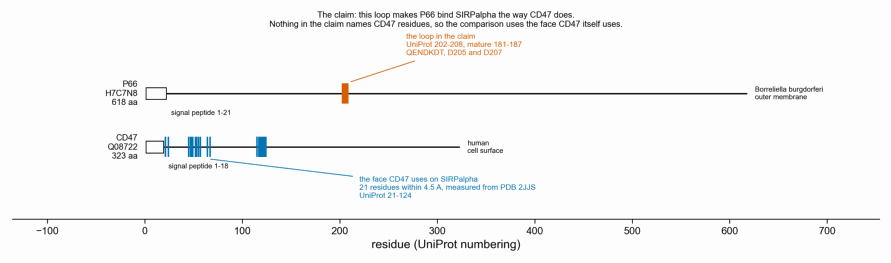

In [2]:
accessions = pl.read_csv(DATA / "01_accessions.csv")
numbering = pl.read_csv(DATA / "01_loop_numbering.csv")
print("Accessions resolved live from UniProt by gene and taxon:")
print(accessions)
print("\nThe paper's mature numbering mapped onto the UniProt entry:")
print(numbering)
show("276h_claim_diagram", aspect=0.28)

**Figure 276h.** The claim as a picture: which stretch of which protein, and against what.
`figures/276h_claim_diagram.png`. Each protein is a line with open boxes for its UniProt
features, the way InterPro draws one. Vermillion is the P66 loop the claim names; blue is
the CD47 face measured in section 2. Nothing has been measured yet at this point; the
figure only says what the comparison will be between.

## 1. How much of P66's model can be trusted

A comparison of shapes is only as good as the shapes. P66 has no experimental structure, so
every comparison below rests on an AlphaFold model, and the model's own confidence decides
how much any of it is worth. pLDDT is AlphaFold's per-residue confidence on a 0-100 scale;
AlphaFold calls anything under 50 "very low", meaning the residue's position should not be
relied on at all.

This is the single most important number in the notebook, so it comes first.

Models used, at the version the AlphaFold API reported today:
shape: (2, 6)
┌─────────┬──────────────┬─────────┬────────────────────┬────────────┬───────────────┐
│ protein ┆ entry_id     ┆ version ┆ all_versions       ┆ mean_plddt ┆ model_created │
│ ---     ┆ ---          ┆ ---     ┆ ---                ┆ ---        ┆ ---           │
│ str     ┆ str          ┆ i64     ┆ str                ┆ f64        ┆ str           │
╞═════════╪══════════════╪═════════╪════════════════════╪════════════╪═══════════════╡
│ P66     ┆ AF-H7C7N8-F1 ┆ 6       ┆ [3, 4, 5, 6]       ┆ 29.0       ┆ 2022-06-01    │
│ CD47    ┆ AF-Q08722-F1 ┆ 6       ┆ [1, 2, 3, 4, 5, 6] ┆ 86.31      ┆ 2025-08-01    │
└─────────┴──────────────┴─────────┴────────────────────┴────────────┴───────────────┘

Confidence summary:
shape: (1, 5)
┌──────────────────────────┬────────────────────────────┬──────────────────────┬───────────────────────┬─────────────────────────────┐
│ experimental_p66_entries ┆ n_experimental_p66_entries ┆ 

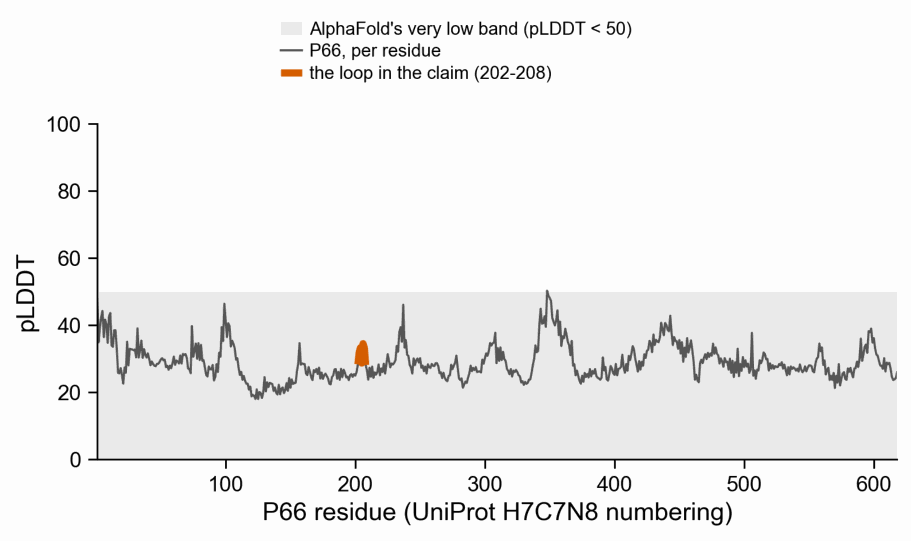

In [3]:
conf = pl.read_csv(DATA / "02_model_confidence_summary.csv")
models = pl.read_csv(DATA / "02_alphafold_models.csv")
plddt = pl.read_csv(DATA / "02_p66_plddt.csv")
start, end = int(numbering["full_start"][0]), int(numbering["full_end"][0])
loop_plddt = plddt.filter(pl.col("full_position").is_between(start, end))

print("Models used, at the version the AlphaFold API reported today:")
print(
    models.select(
        "protein", "entry_id", "version", "all_versions", "mean_plddt", "model_created"
    )
)
print("\nConfidence summary:")
print(conf)
print(f"\nThe loop, residue by residue (UniProt {start}-{end}):")
print(loop_plddt)
show("276a_p66_model_confidence")

**Figure 276a.** P66's model confidence along the chain, with the claimed loop marked.
`figures/276a_p66_model_confidence.png`.

**How to read it.** The grey band is AlphaFold's "very low" region. The whole P66 trace sits
inside it.

**What it says.** The AlphaFold model of P66 has a mean pLDDT of 29.0, the number AlphaFold
itself reports for the entry, and 99.8% of its 618 residues are below 50. The loop in the
claim is no exception: mean 31.2, range 28.1 to 34.5. The human CD47 model, fetched the
same way in the same run, has a mean pLDDT of 86.3, so this is a property of the P66 model
and not of how the files are being read. A search of the PDB found no experimental
structure of P66 at all.

The model is not formless, though: 42% of its residues are called β-strand from the
backbone geometry (section 5), which is what a β-barrel should look like, and section 4
shows Foldseek recovering outer-membrane β-barrels from it. Low confidence here means the
details cannot be trusted, not that the file is noise.

This weakens every structural comparison below, and it weakens them in both directions. A
model this uncertain cannot show that P66 resembles CD47, and it also cannot firmly show
that it does not. Section 8 returns to this as the strongest argument against the result.

## 2. CD47's SIRPα-binding face, measured rather than quoted

Rather than copy a residue list out of a paper, the face is measured from a crystal
structure of the two proteins together. RCSB was searched for CD47 / SIRPα complexes and
the entries ranked by resolution; entries whose own description calls a chain engineered,
high-affinity or a variant were set aside, because a mutant interface is not the wild-type
face the claim is about.

The face is defined as the CD47 residues with any heavy atom within 4.5 Å of any heavy atom
of SIRPα. Both CD47 copies in the crystal were tried against both SIRPα copies, and the
pair with the most contacts is the one reported; the others are crystal packing.

RCSB hits, best resolution first:
shape: (13, 7)
┌────────┬─────────────────────┬────────┬──────────┬───────────────┬────────────────────┬─────────────────────────────────┐
│ pdb_id ┆ resolution_angstrom ┆ method ┆ has_cd47 ┆ has_sirpalpha ┆ engineered_partner ┆ title                           │
│ ---    ┆ ---                 ┆ ---    ┆ ---      ┆ ---           ┆ ---                ┆ ---                             │
│ str    ┆ f64                 ┆ str    ┆ bool     ┆ bool          ┆ bool               ┆ str                             │
╞════════╪═════════════════════╪════════╪══════════╪═══════════════╪════════════════════╪═════════════════════════════════╡
│ 6LYC   ┆ 1.36                ┆ X-ray  ┆ false    ┆ true          ┆ false              ┆ Crystal structure of the NOD S… │
│ 6NMT   ┆ 1.83                ┆ X-ray  ┆ false    ┆ true          ┆ true               ┆ Non-Blocking Fab 3 anti-SIRP-a… │
│ 2JJS   ┆ 1.85                ┆ X-ray  ┆ true     ┆ true          ┆ false         

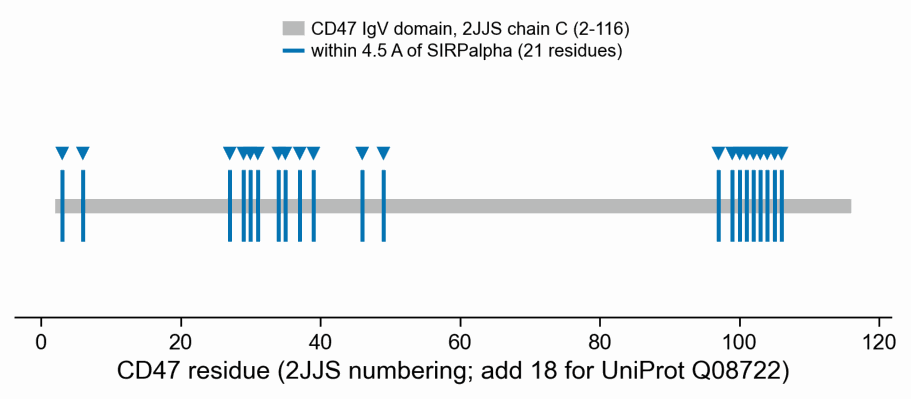

In [4]:
hits = pl.read_csv(DATA / "03_rcsb_search.csv")
chosen = pl.read_csv(DATA / "03_chosen_complex.csv")
face = pl.read_csv(DATA / "04_cd47_sirpalpha_face.csv")
domain = pl.read_csv(DATA / "05_cd47_igv_domain.csv")

print("RCSB hits, best resolution first:")
print(
    hits.select(
        "pdb_id",
        "resolution_angstrom",
        "method",
        "has_cd47",
        "has_sirpalpha",
        "engineered_partner",
        "title",
    )
)
print("\nThe entry used:")
print(
    chosen.select(
        "pdb_id",
        "title",
        "method",
        "resolution_angstrom",
        "cd47_chains",
        "sirpalpha_chains",
    )
)
print("\nThe CD47 chain taken as the IgV domain:")
print(domain)
print(f"\nThe binding face, {face.height} CD47 residues within 4.5 A of SIRPalpha:")
print(face)
show("276e_cd47_binding_face_map")

**Figure 276e.** Where the face residues sit along CD47's IgV domain.
`figures/276e_cd47_binding_face_map.png`.

**What it says.** PDB 2JJS, human CD47 with human SIRPα at 1.85 Å
([Hatherley et al. 2008](https://doi.org/10.1016/j.molcel.2008.05.026)), chain C against
chain A. 21 CD47 residues lie within 4.5 Å of SIRPα, in 11 separate runs along the chain,
the longest being 2JJS 99-106 (UniProt 117-124), 8 residues. The closest contact is 2.59 Å.
The face is not one flat patch but the N-terminus plus several loops at one end of the
domain, which is what the Hatherley paper describes.

[PR 96](https://github.com/seanome/2024-kmerseek-analysis/pull/96) measured the same face
from the same entry at a 4 Å cutoff and found 20 residues with a run at UniProt 115-124.
The two agree: the looser cutoff here adds one residue.

## 3. Comparison 1, the whole fold

US-align ([Zhang et al. 2022](https://doi.org/10.1038/s41592-022-01585-1)) aligns P66's
whole AlphaFold model against CD47's IgV domain. TM-score runs from 0 to 1 and depends on
which structure it is divided by, so both are reported; with a 618-residue query against a
115-residue domain, only the normalisation by CD47 is interpretable, and that is the one
quoted. TM-score at or above 0.5 is the usual line for "the same fold".

**The background.** 20 domains were drawn at random, with a fixed seed, from the 239
immunoglobulin-like domains of SCOPe 2.08 superfamily b.1.1 in the ASTRAL 40% set, which
holds representatives at a 40% sequence-identity threshold. These domains share an
immunoglobulin superfamily; that threshold does not make them unrelated to each other
or to CD47. Each is aligned to the same CD47 domain the same way. These are the scores a
genuine immunoglobulin relative of CD47 earns.

The claimed pair, US-align:
shape: (1, 7)
┌─────────────────────────────────┬─────────────────────┬──────────────────────┬────────────────┬───────────────┬──────────────┬───────────────┐
│ comparison                      ┆ tm_score_norm_query ┆ tm_score_norm_target ┆ aligned_length ┆ rmsd_angstrom ┆ query_length ┆ target_length │
│ ---                             ┆ ---                 ┆ ---                  ┆ ---            ┆ ---           ┆ ---          ┆ ---           │
│ str                             ┆ f64                 ┆ f64                  ┆ i64            ┆ f64           ┆ i64          ┆ i64           │
╞═════════════════════════════════╪═════════════════════╪══════════════════════╪════════════════╪═══════════════╪══════════════╪═══════════════╡
│ P66 AlphaFold model vs CD47 Ig… ┆ 0.09118             ┆ 0.34233              ┆ 68             ┆ 4.34          ┆ 618          ┆ 115           │
└─────────────────────────────────┴─────────────────────┴──────────────────────┴────────

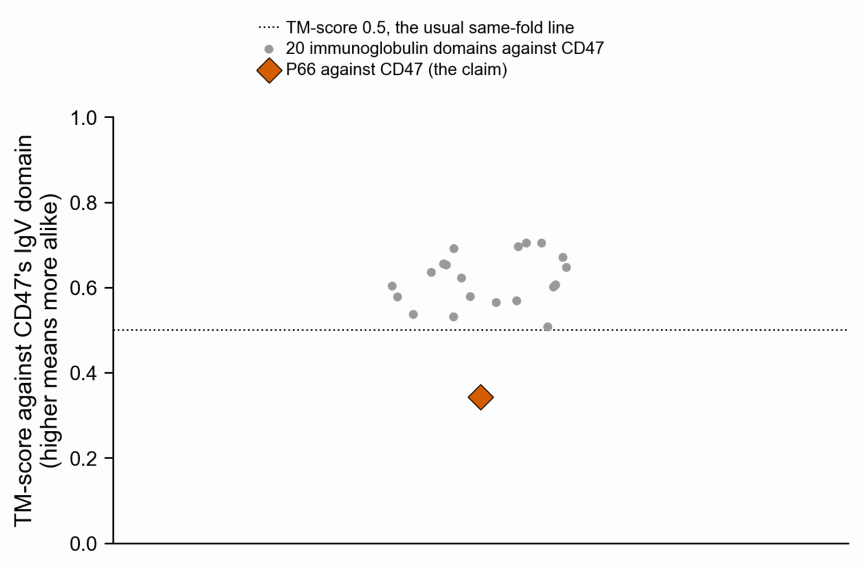

In [5]:
claimed = pl.read_csv(DATA / "05_wholefold_claimed.csv")
bg = pl.read_csv(DATA / "05_wholefold_background.csv")
pool = pl.read_csv(DATA / "05_ig_superfamily_pool.csv")

print("The claimed pair, US-align:")
print(claimed)
print(
    f"\nBackground: {bg.height} immunoglobulin domains drawn from "
    f"{pool.height} in SCOPe b.1.1, ASTRAL-40:"
)
print(
    bg.select(
        "comparison",
        "sccs",
        "tm_score_norm_target",
        "aligned_length",
        "rmsd_angstrom",
        "query_length",
        "description",
    )
)
claim_tm = claimed["tm_score_norm_target"][0]
print(f"\nClaimed pair TM-score (normalised by CD47): {claim_tm}")
print(
    f"Background median {bg['tm_score_norm_target'].median():.3f}, "
    f"range {bg['tm_score_norm_target'].min():.3f} to "
    f"{bg['tm_score_norm_target'].max():.3f}"
)
print(
    f"Background domains scoring above the claimed pair: "
    f"{(bg['tm_score_norm_target'] > claim_tm).sum()} of {bg.height}"
)
show("276c_wholefold_tmscore_background")

**Figure 276c.** The claimed pair against the 20-domain background.
`figures/276c_wholefold_tmscore_background.png`.

**What it says.** P66 against CD47's IgV domain scores TM-score 0.342 normalised by CD47,
over 68 aligned residues at 4.34 Å RMSD. That is below 0.5, so not the same fold by the
usual line. All 20 immunoglobulin domains score higher, from 0.507 to 0.704, median 0.614,
and the lowest of them still clears 0.5.

**The decision.** The claimed pair does not beat the background. It is not merely at the
bottom of the range; it is outside it, below every one of 20.

## 4. Comparison 2, Foldseek

Foldseek ([van Kempen et al. 2023](https://doi.org/10.1038/s41587-023-01773-0), version
10.941cd33) searches P66's model twice: against the whole PDB, using Foldseek's own PDB100
database built 2025-01-01, and directly against CD47's AlphaFold model. The second search
uses `--exhaustive-search` with no E-value ceiling, which forces an alignment to be
reported whether or not one is worth reporting, so that the pair cannot simply fall below
a threshold and vanish.

**The control that makes the PDB search mean something.** 2JJS is in the database. All four
of its chains are there, so if CD47 is absent from P66's hit list that is a real negative
and not a gap in the database.

P66 against the PDB, 12 strongest hits:
shape: (12, 11)
┌───────────────────────┬──────────────────┬────────┬──────┬───┬────────┬──────┬────────┬───────┐
│ query                 ┆ target           ┆ evalue ┆ bits ┆ … ┆ tstart ┆ tend ┆ alnlen ┆ prob  │
│ ---                   ┆ ---              ┆ ---    ┆ ---  ┆   ┆ ---    ┆ ---  ┆ ---    ┆ ---   │
│ str                   ┆ str              ┆ f64    ┆ i64  ┆   ┆ i64    ┆ i64  ┆ i64    ┆ f64   │
╞═══════════════════════╪══════════════════╪════════╪══════╪═══╪════════╪══════╪════════╪═══════╡
│ AF-H7C7N8-F1-model_v6 ┆ 5o68-assembly2_D ┆ 0.128  ┆ 45   ┆ … ┆ 36     ┆ 241  ┆ 337    ┆ 0.326 │
│ AF-H7C7N8-F1-model_v6 ┆ 1bp1-assembly1_A ┆ 0.128  ┆ 26   ┆ … ┆ 18     ┆ 382  ┆ 481    ┆ 0.063 │
│ AF-H7C7N8-F1-model_v6 ┆ 5o68-assembly3_G ┆ 0.1349 ┆ 45   ┆ … ┆ 36     ┆ 241  ┆ 341    ┆ 0.326 │
│ AF-H7C7N8-F1-model_v6 ┆ 5o65-assembly1_C ┆ 0.1581 ┆ 37   ┆ … ┆ 38     ┆ 241  ┆ 342    ┆ 0.164 │
│ AF-H7C7N8-F1-model_v6 ┆ 2bi0-assembly1_A ┆ 0.217  ┆ 22   ┆ …

CD47 / SIRPalpha entries among the hits: 0

P66 against CD47's AlphaFold model, forced:
shape: (1, 11)
┌───────────────────────┬───────────────────────┬────────┬──────┬───┬────────┬──────┬────────┬──────┐
│ query                 ┆ target                ┆ evalue ┆ bits ┆ … ┆ tstart ┆ tend ┆ alnlen ┆ prob │
│ ---                   ┆ ---                   ┆ ---    ┆ ---  ┆   ┆ ---    ┆ ---  ┆ ---    ┆ ---  │
│ str                   ┆ str                   ┆ f64    ┆ i64  ┆   ┆ i64    ┆ i64  ┆ i64    ┆ f64  │
╞═══════════════════════╪═══════════════════════╪════════╪══════╪═══╪════════╪══════╪════════╪══════╡
│ AF-H7C7N8-F1-model_v6 ┆ AF-Q08722-F1-model_v6 ┆ 3.047  ┆ 3    ┆ … ┆ 111    ┆ 126  ┆ 22     ┆ 0.0  │
└───────────────────────┴───────────────────────┴────────┴──────┴───┴────────┴──────┴────────┴──────┘


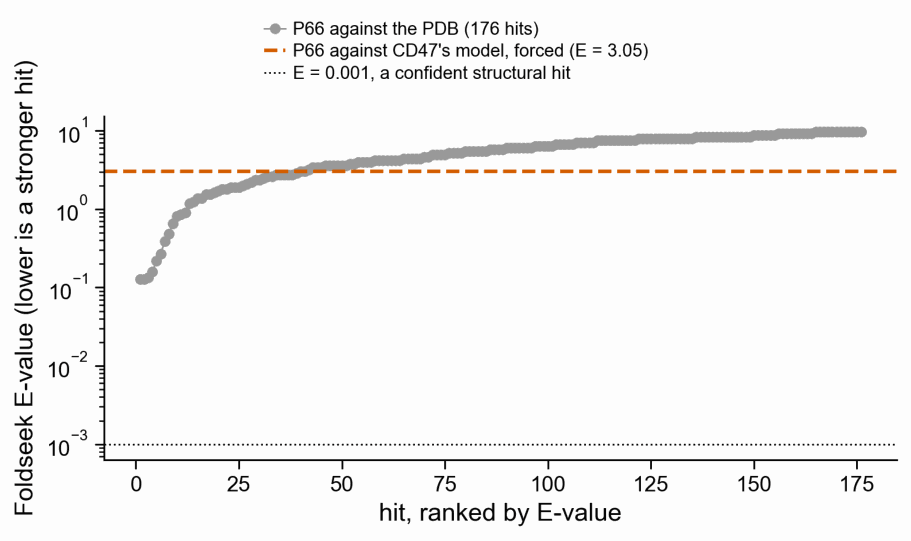

In [6]:
pdb_hits = pl.read_csv(DATA / "06_foldseek_vs_pdb.csv")
pair_hit = pl.read_csv(DATA / "06_foldseek_vs_cd47_model.csv")

print("P66 against the PDB, 12 strongest hits:")
print(pdb_hits.sort("evalue").head(12))
print(
    f"\n{pdb_hits.height} hits in total; best E-value "
    f"{pdb_hits['evalue'].min()}; hits below E = 0.001: "
    f"{(pdb_hits['evalue'] < 0.001).sum()}"
)
cd47_entries = pdb_hits.filter(
    pl.col("target").str.contains("(?i)2jjs|4cmm|2jjt|4kjy|7ygg")
)
print(f"CD47 / SIRPalpha entries among the hits: {cd47_entries.height}")
print("\nP66 against CD47's AlphaFold model, forced:")
print(pair_hit)
show("276f_foldseek_p66_vs_pdb")

**Figure 276f.** Foldseek's E-values for P66 against the PDB, ranked.
`figures/276f_foldseek_p66_vs_pdb.png`.

**What it says.** Foldseek returns 176 hits for P66 in the PDB. Not one reaches E = 0.001,
and the best is E = 0.128. The strongest hits are bacterial outer-membrane β-barrels: 5o68
and 5o65, the *Pseudomonas* functional amyloid secretion protein FapF, and 1thq, the outer
membrane enzyme PagP. That is the right answer for what P66 is, and it shows the search is
working rather than returning noise. No CD47 or SIRPα entry appears anywhere in the list,
although 2JJS is in the database.

Forced against CD47's model, the single reported alignment has E = 3.05, probability 0.00,
and covers P66 526-547 against CD47 111-126: 22 residues at the far end of P66, nowhere
near the loop at 202-208. The alignment's local TM-score of 0.579 is measured over those 22
residues only and says nothing about the two proteins.

## 5. Comparison 3, the loop against the face

The binding face is 11 separate runs, not one stretch, so "superpose the loop on the face"
needs a definite meaning. Here it is: the loop's 7 residues are superposed, backbone atoms
N, CA, C and O in sequence order, onto every run of 7 consecutive CD47 residues that
includes at least one face residue, and the best RMSD over those windows is reported.

**The background.** 10 other loops of P66, each 7 residues long, each a run of coil, none
overlapping the claimed loop, drawn at random with the same fixed seed. Coil is assigned
from CA geometry, because DSSP is not installed on this machine; the criteria are the
CA-distance ranges P-SEA uses, and **I cannot verify a citation for this claim** — a PubMed
search for the P-SEA paper returned nothing. Each background loop gets the same treatment
against the same windows.

Two things to know about this background before reading the result. The model is 53% coil,
42% strand and 5% helix, so the coil runs the background is drawn from are real coil
between strands and not one long disordered chain; that also fits Foldseek calling P66 a
β-barrel in section 4. But two pairs of the ten windows overlap each other (117-123 with
122-128, and 563-569 with 565-571), so there are eight independent stretches rather than
ten, and the background spread is slightly narrower than ten separate draws would give.

The claimed loop on every face window, best first:
shape: (10, 5)
┌──────────────┬────────────┬────────────────────────┬──────────────────┬──────────────┐
│ window_start ┆ window_end ┆ backbone_rmsd_angstrom ┆ n_backbone_atoms ┆ loop         │
│ ---          ┆ ---        ┆ ---                    ┆ ---              ┆ ---          │
│ i64          ┆ i64        ┆ f64                    ┆ i64              ┆ str          │
╞══════════════╪════════════╪════════════════════════╪══════════════════╪══════════════╡
│ 29           ┆ 35         ┆ 1.912462               ┆ 28               ┆ claimed loop │
│ 25           ┆ 31         ┆ 1.942834               ┆ 28               ┆ claimed loop │
│ 27           ┆ 33         ┆ 2.001426               ┆ 28               ┆ claimed loop │
│ 33           ┆ 39         ┆ 2.103826               ┆ 28               ┆ claimed loop │
│ 100          ┆ 106        ┆ 2.12774                ┆ 28               ┆ claimed loop │
│ 24           ┆ 30         ┆ 2.22591       

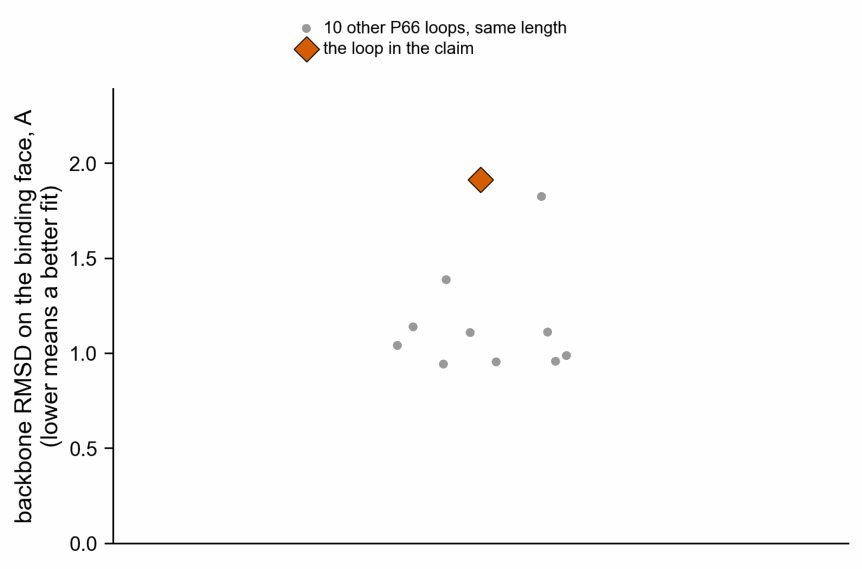

In [7]:
claimed_rmsd = pl.read_csv(DATA / "07_claimed_loop_vs_face.csv")
bg_loops = pl.read_csv(DATA / "07_background_loops_vs_face.csv")
sup = pl.read_csv(DATA / "09_superposition_summary.csv")

print("The claimed loop on every face window, best first:")
print(claimed_rmsd.head(10))
best = claimed_rmsd.sort("backbone_rmsd_angstrom").row(0, named=True)
print(
    f"\nBest: {best['backbone_rmsd_angstrom']:.2f} A on CD47 "
    f"{best['window_start']}-{best['window_end']}"
)
print(f"\nBackground, {bg_loops.height} other P66 loops of the same length:")
print(bg_loops)
print(
    f"\nBackground median {bg_loops['backbone_rmsd_angstrom'].median():.2f} A, "
    f"best {bg_loops['backbone_rmsd_angstrom'].min():.2f} A"
)
print(
    f"Background loops fitting better than the claimed loop: "
    f"{(bg_loops['backbone_rmsd_angstrom'] < best['backbone_rmsd_angstrom']).sum()}"
    f" of {bg_loops.height}"
)
show("276d_loop_to_face_rmsd_background")

**Figure 276d.** The claimed loop against 10 other P66 loops.
`figures/276d_loop_to_face_rmsd_background.png`.

**What it says.** The claimed loop's best fit is 1.91 Å backbone RMSD, on CD47 29-35. All 10
other P66 loops fit better, median 1.07 Å, best 0.94 Å.

**The decision.** The claimed loop does not beat the background; it is the worst of the
eleven. Read plainly, a 7-residue backbone can be laid onto a 7-residue backbone at about
1 Å whatever the two are, and the claimed loop does not even manage the ordinary amount.

Where the loop actually lands once the two proteins are superposed:
shape: (1, 9)
┌────────────────────────────────┬────────────────────────────────┬─────────────────────────────────┬─────────────────────┬───┬────────────────┬───────────────┬──────────────┬───────────────┐
│ loop_to_face_centroid_angstrom ┆ cd47_igv_widest_ca_ca_angstrom ┆ comparison                      ┆ tm_score_norm_query ┆ … ┆ aligned_length ┆ rmsd_angstrom ┆ query_length ┆ target_length │
│ ---                            ┆ ---                            ┆ ---                             ┆ ---                 ┆   ┆ ---            ┆ ---           ┆ ---          ┆ ---           │
│ f64                            ┆ f64                            ┆ str                             ┆ f64                 ┆   ┆ i64            ┆ f64           ┆ i64          ┆ i64           │
╞════════════════════════════════╪════════════════════════════════╪═════════════════════════════════╪═════════════════════╪═══╪════════════════╪══════

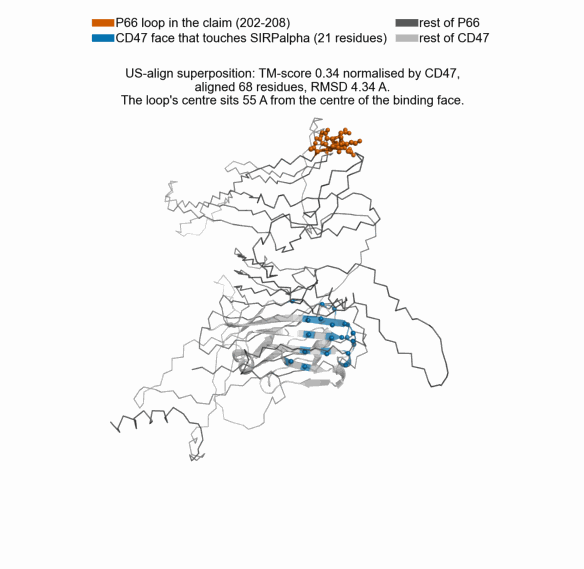

In [8]:
print("Where the loop actually lands once the two proteins are superposed:")
print(sup)
show("276b_p66_cd47_superposition")

**Figure 276b.** The two structures superposed by US-align, with the loop and the face
coloured. `figures/276b_p66_cd47_superposition.png`.

**How to read it.** Vermillion is the P66 loop in the claim, blue is CD47's SIRPα-binding
face, dark grey is the rest of P66 as a thin trace, light grey is the rest of CD47.

**What it says.** In the best whole-fold superposition the two structures have, the centre
of the loop sits 55 Å from the centre of the binding face. CD47's IgV domain is only 45 Å across at its widest,
measured here as the longest CA-to-CA distance in it, so the loop does not land on the
wrong part of the face: it lands off the domain entirely. The thin grey trace wandering across the picture is the rest of P66, drawn
as it is modelled, and it is a fair picture of what a mean pLDDT of 29 looks like.

## 6. What kmerseek already says here, across every alphabet

This is a negative result and is kept as one.
[PR 96](https://github.com/seanome/2024-kmerseek-analysis/pull/96),
[notebook 245](./245_p66_cd47_pair_coordinates.ipynb), mapped every k-mer P66 and CD47
share onto both sequences: **none of the 326 shared k-mers touches the P66 loop**. That
sweep was not only the two-letter alphabets. It covered **16 alphabets over 27 settings**,
from `protein20`-adjacent `hsdm17` and `mmseqs12` down through `sdm12`, `funcgroups8`,
`gbmr7`, `dayhoff6`, `wwmj5`, `polarity4` and `gbmr4` to the HP family. The count is zero
in every one of them.

So the question is what the larger alphabets see there, and the answer has two parts.

**Part one: eight alphabets write the loop as one repeated class, not six.** The loop is
`QENDKDT`, seven polar residues. All six two-letter alphabets write it as one letter, and
so do `hp_lehninger_hpc3` with 3 classes and `gbmr4` with 4, because `gbmr4` pools
`ADKERNTSQ` into a single class that swallows all seven residues. In those eight a k-mer on
the loop carries no pattern at all: it cannot be told from any other polar stretch of the
same length in any protein.

**Part two: in the eleven alphabets where the loop is a varied string, its k-mers still do
not exist in CD47.** `polarity4` writes it `BCBCDCB`, `funcgroups8` writes it `FGFGHGB`,
`protein20` of course keeps all seven residues distinct. A varied string could carry a
signal, so a class string alone cannot settle it; both proteins have to be encoded and
looked at. Doing that for all 19 alphabets in the repo's table at every k from 5 to 25:
at **all 27 settings PR 96 searched, zero k-mers covering the loop occur anywhere in
CD47**, and in 9 of the 11 varied alphabets none occurs at any k in that range. The two
exceptions are worth naming rather than hiding: `polarity4` has exactly one, and `gbmr7`
two, all at k = 5, and section 6b prints them residue by residue.

**This changes how PR 96's number should be read.** That notebook reported 0 observed
against 8.5 expected, binomial p = 0.00035, and called it "fewer than chance". The expected
count assumes a shared k-mer was available to land on the loop by chance. None was. The
zero is forced by the encoding and by which settings were searched, not evidence that
something avoids the loop. PR 96 said its pooled test should be read as a direction rather
than a p-value to defend, and this is why.

A loop k-mer does reach CD47, but only at k of 13 or less and only in the alphabets that
write the loop as one repeated class, where a run of identical letters matches any polar
stretch. That is a match without information, and PR 96 searched no setting there.

**What this does and does not support.** Convergent mimicry is the hypothesis that two
unrelated sequences arrived at the same shape. It predicts no sequence signal, so a zero
here is consistent with mimicry being real. It is equally consistent with mimicry not being
real. On this evidence it supports neither, and after the stronger reading above it supports
neither even weakly: no alphabet in the sweep could have found anything on this loop. The
three structural comparisons are what can separate the two, and they point the other way.

The loop in every alphabet. Grid letters are class numbers relabelled
A, B, C..., not residues; in protein20 that relabelling is one-to-one.
shape: (19, 5)
┌──────────────────────────┬───────────┬───────────────────┬────────────────────────────┬──────────────────────┐
│ alphabet                 ┆ n_classes ┆ loop_class_string ┆ n_distinct_classes_in_loop ┆ found_over_k_5_to_25 │
│ ---                      ┆ ---       ┆ ---               ┆ ---                        ┆ ---                  │
│ str                      ┆ i64       ┆ str               ┆ i64                        ┆ i64                  │
╞══════════════════════════╪═══════════╪═══════════════════╪════════════════════════════╪══════════════════════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ BBBBBBB           ┆ 1                          ┆ 36                   │
│ hp_lehninger2            ┆ 2         ┆ BBBBBBB           ┆ 1                          ┆ 43                   │
│ hp_lehninger_c_nonpolar2 ┆ 2         ┆ BBBBBBB     

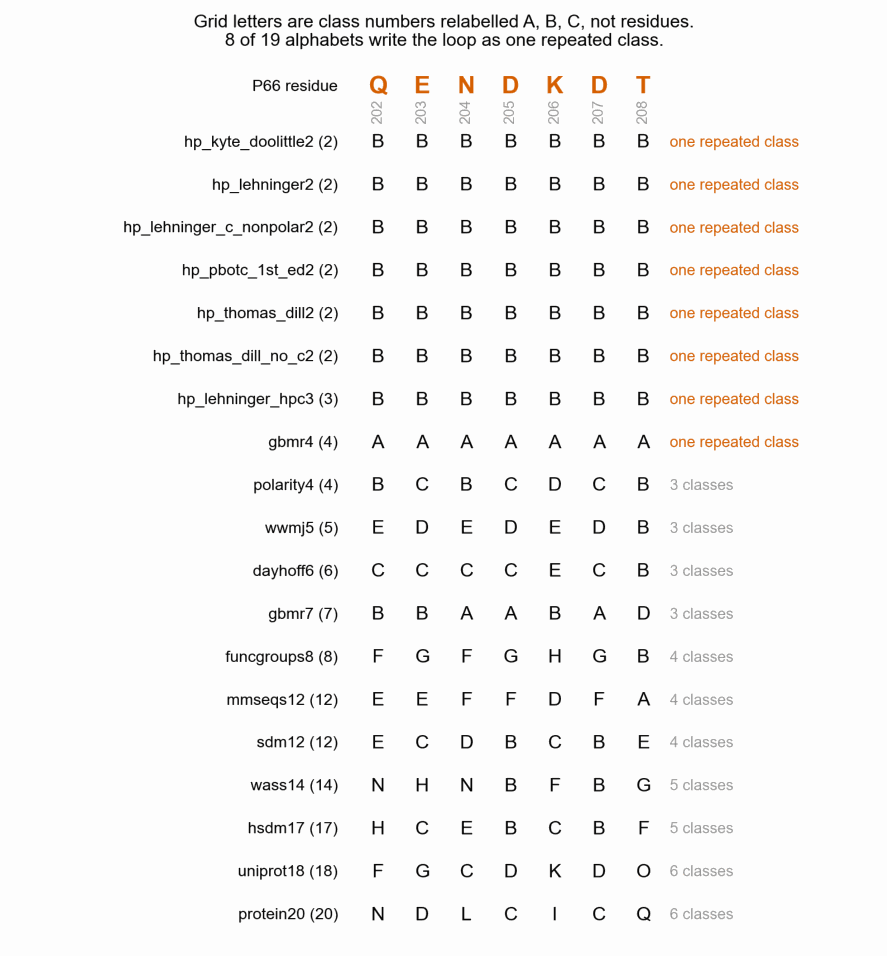

In [9]:
reach = pl.read_csv(DATA / "09_loop_kmer_reach_all_alphabets.csv")
per_alphabet = (
    reach.group_by("alphabet", "n_classes")
    .agg(
        pl.col("loop_class_string").first(),
        pl.col("n_distinct_classes_in_loop").first(),
        pl.col("n_covering_kmers_found_in_cd47").sum().alias("found_over_k_5_to_25"),
    )
    .sort("n_classes", "alphabet")
)
print("The loop in every alphabet. Grid letters are class numbers relabelled")
print("A, B, C..., not residues; in protein20 that relabelling is one-to-one.")
print(per_alphabet)
n_uniform = (per_alphabet["n_distinct_classes_in_loop"] == 1).sum()
print(
    f"\nAlphabets writing the loop as one repeated class: "
    f"{n_uniform} of {per_alphabet.height}"
)
print(
    f"Varied alphabets with no loop k-mer in CD47 at any k from 5 to 25: "
    f"{per_alphabet.filter((pl.col('n_distinct_classes_in_loop') > 1) & (pl.col('found_over_k_5_to_25') == 0)).height}"
    f" of {per_alphabet.filter(pl.col('n_distinct_classes_in_loop') > 1).height}"
)
reachable = reach.filter(pl.col("n_covering_kmers_found_in_cd47") > 0)
print(
    f"Highest k at which any loop k-mer occurs in CD47: {reachable['ksize'].max()}, "
    f"in {sorted(reachable.filter(pl.col('ksize') == reachable['ksize'].max())['alphabet'].to_list())}"
)
show("276g_loop_class_strings_all_alphabets", aspect=1.05)

**Figure 276g.** The loop written out in every alphabet, smallest to largest.
`figures/276g_loop_class_strings_all_alphabets.png`. The grid letters are class numbers
relabelled A, B, C and are not residues; the vermillion row at the top is the real
sequence.

Every setting PR 96 searched, and whether a loop k-mer existed to be found:
shape: (27, 4)
┌──────────────────────────┬───────┬───────────────────────────┬────────────────────────────────┐
│ alphabet                 ┆ ksize ┆ n_p66_kmers_covering_loop ┆ n_covering_kmers_found_in_cd47 │
│ ---                      ┆ ---   ┆ ---                       ┆ ---                            │
│ str                      ┆ i64   ┆ i64                       ┆ i64                            │
╞══════════════════════════╪═══════╪═══════════════════════════╪════════════════════════════════╡
│ dayhoff6                 ┆ 7     ┆ 13                        ┆ 0                              │
│ funcgroups8              ┆ 6     ┆ 12                        ┆ 0                              │
│ funcgroups8              ┆ 7     ┆ 13                        ┆ 0                              │
│ gbmr4                    ┆ 10    ┆ 16                        ┆ 0                              │
│ gbmr7                    

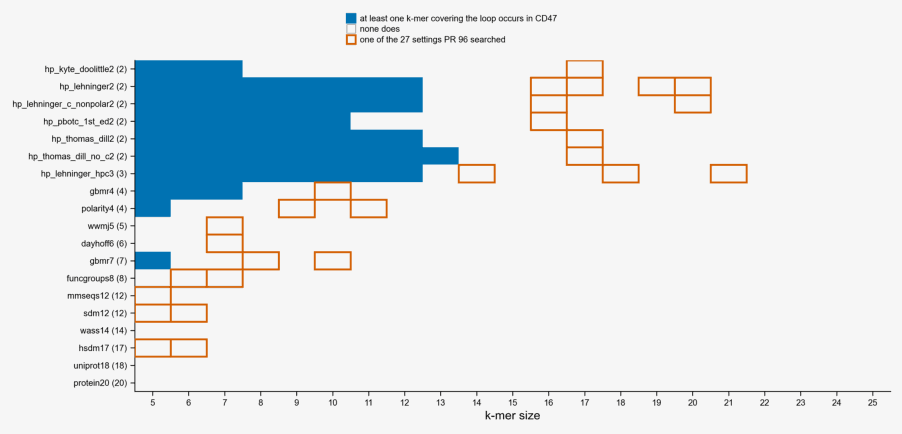

In [10]:
print("Every setting PR 96 searched, and whether a loop k-mer existed to be found:")
pr96 = [
    ("dayhoff6", 7),
    ("funcgroups8", 6),
    ("funcgroups8", 7),
    ("gbmr4", 10),
    ("gbmr7", 8),
    ("gbmr7", 10),
    ("hp_kyte_doolittle2", 17),
    ("hp_lehninger2", 16),
    ("hp_lehninger2", 17),
    ("hp_lehninger2", 19),
    ("hp_lehninger2", 20),
    ("hp_lehninger_c_nonpolar2", 16),
    ("hp_lehninger_c_nonpolar2", 20),
    ("hp_lehninger_hpc3", 14),
    ("hp_lehninger_hpc3", 18),
    ("hp_lehninger_hpc3", 21),
    ("hp_pbotc_1st_ed2", 16),
    ("hp_thomas_dill2", 17),
    ("hp_thomas_dill_no_c2", 17),
    ("hsdm17", 5),
    ("hsdm17", 6),
    ("mmseqs12", 5),
    ("polarity4", 9),
    ("polarity4", 11),
    ("sdm12", 5),
    ("sdm12", 6),
    ("wwmj5", 7),
]
keys = [f"{a}@{k}" for a, k in pr96]
swept = reach.filter(
    pl.concat_str(
        [pl.col("alphabet"), pl.col("ksize").cast(pl.Utf8)], separator="@"
    ).is_in(keys)
)
print(
    swept.select(
        "alphabet",
        "ksize",
        "n_p66_kmers_covering_loop",
        "n_covering_kmers_found_in_cd47",
    ).sort("alphabet", "ksize")
)
print(
    f"\n{swept.height} settings; P66 k-mers covering the loop: "
    f"{swept['n_p66_kmers_covering_loop'].sum()}; of those, occurring in CD47: "
    f"{swept['n_covering_kmers_found_in_cd47'].sum()}"
)
show("276i_loop_kmer_reach_by_alphabet_and_k", aspect=0.47)

**Figure 276i.** Whether any k-mer covering the loop occurs in CD47, for every alphabet and
k. `figures/276i_loop_kmer_reach_by_alphabet_and_k.png`.

**How to read it.** One cell per alphabet and k. Blue means at least one of P66's
loop-covering k-mers occurs somewhere in CD47, so a shared k-mer on the loop was possible
there. Grey means none does, so no search at that setting could have found one whatever the
biology. A vermillion outline marks one of the 27 settings PR 96 searched.

**What it says.** Every vermillion box sits on a grey cell. The blue region is confined to
low k in the alphabets that write the loop as one repeated class, and PR 96 searched none of
it. Its zero is therefore a statement about where it looked, not about the loop.

## 6b. The shared k-mers on the loop, printed out

A count is not enough to judge a match. Every shared k-mer that covers the loop, in every
alphabet, written as the two spans with their residues. Only three of them are in an
alphabet where the loop is a varied string, and all three are at k = 5, which is shorter
than any setting in the project.

1108 shared k-mers cover the loop in total; 1105 are in the 8 alphabets that write it as one repeated class.

The 3 in an alphabet where the loop is a varied string:
shape: (3, 11)
┌───────────┬───────┬───────────┬─────────┬───┬───────────────┬──────────────┬──────────────────────┬───────────────────────┐
│ alphabet  ┆ ksize ┆ p66_start ┆ p66_end ┆ … ┆ cd47_residues ┆ class_string ┆ n_identical_residues ┆ loop_residues_covered │
│ ---       ┆ ---   ┆ ---       ┆ ---     ┆   ┆ ---           ┆ ---          ┆ ---                  ┆ ---                   │
│ str       ┆ i64   ┆ i64       ┆ i64     ┆   ┆ str           ┆ str          ┆ i64                  ┆ str                   │
╞═══════════╪═══════╪═══════════╪═════════╪═══╪═══════════════╪══════════════╪══════════════════════╪═══════════════════════╡
│ gbmr7     ┆ 5     ┆ 199       ┆ 203     ┆ … ┆ NENIL         ┆ ABABB        ┆ 2                    ┆ 202,203               │
│ gbmr7     ┆ 5     ┆ 202       ┆ 206     ┆ … ┆ MMNDE         ┆

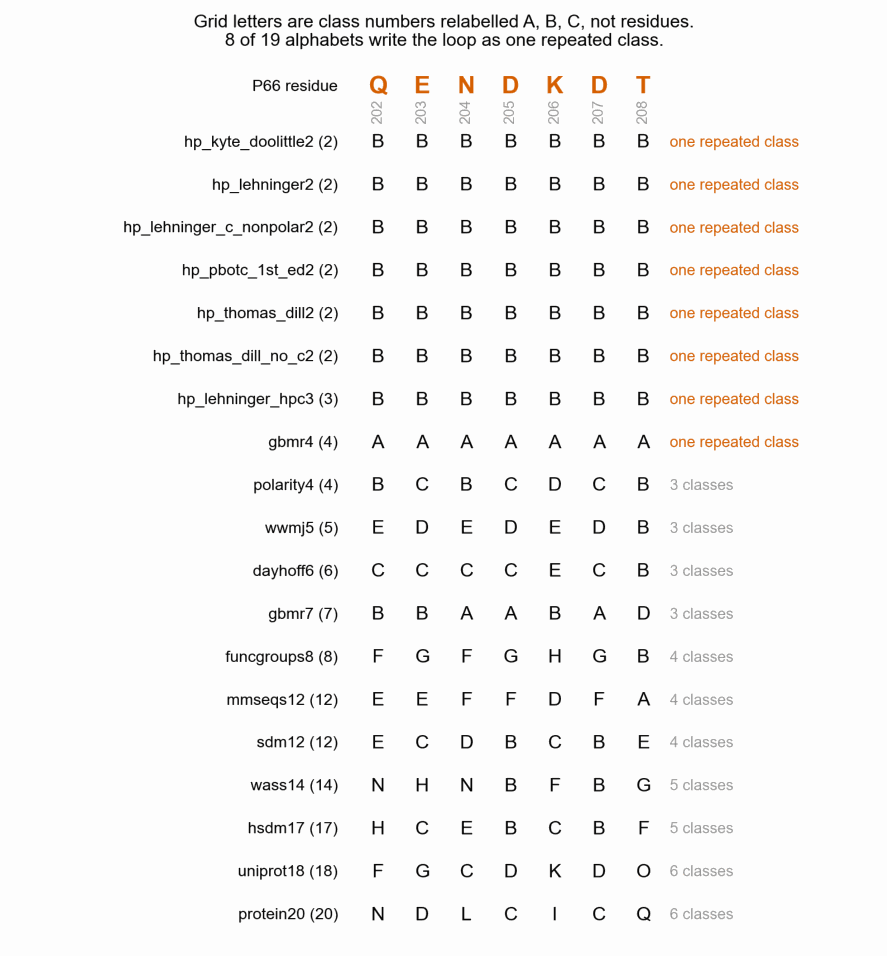

In [11]:
pairs = pl.read_csv(DATA / "10_loop_kmer_pairs.csv")
uniform = (
    pl.read_csv(DATA / "09_loop_kmer_reach_all_alphabets.csv")
    .filter(pl.col("n_distinct_classes_in_loop") == 1)["alphabet"]
    .unique()
    .to_list()
)
varied_pairs = pairs.filter(~pl.col("alphabet").is_in(uniform))
print(
    f"{pairs.height} shared k-mers cover the loop in total; "
    f"{pairs.height - varied_pairs.height} are in the "
    f"{len(uniform)} alphabets that write it as one repeated class."
)
print(f"\nThe {varied_pairs.height} in an alphabet where the loop is a varied string:")
print(
    varied_pairs.select(
        "alphabet",
        "ksize",
        "p66_start",
        "p66_end",
        "p66_residues",
        "cd47_start",
        "cd47_end",
        "cd47_residues",
        "class_string",
        "n_identical_residues",
        "loop_residues_covered",
    )
)
print("\nFor comparison, three from a uniform alphabet at the k where they stop:")
print(
    pairs.filter(pl.col("alphabet").is_in(uniform) & (pl.col("ksize") == 13))
    .select(
        "alphabet",
        "ksize",
        "p66_residues",
        "cd47_residues",
        "class_string",
        "n_identical_residues",
    )
    .head(3)
)
show("276g_loop_class_strings_all_alphabets", aspect=1.05)

**What it says.** In the eight alphabets that write the loop as one repeated class, k-mers
on the loop match CD47 freely up to k = 13, and the pairs show why that is worthless:
`DTPYNKTYQG` against `KSTVPTDFSS` is 0 identical residues out of 10. Both are polar runs
and the alphabet cannot tell them apart.

In the eleven where the loop is a varied string there are exactly three shared k-mers, all
at k = 5: two in `gbmr7` and one in `polarity4`. `funcgroups8` has none at any k from 5 to
25. The best of the three, `gbmr7` k = 5, puts P66 `QENDK` against CD47 `MMNDE` with 2
identical residues and does cover D205. k = 5 in a 7-class alphabet is about 14 bits, well
below anything this project searches at, and PR 96 swept `gbmr7` at k = 8 and 10.

## 6c. Seed-and-extend, which exact k-mers cannot do

Everything above tests exact k-mers, and exact matching has a hard floor: if no k-mer on
the loop exists in CD47, no amount of searching finds one. Seed-and-extend does not have
that floor. A seed that lands beside the loop extends across it, and the extension tolerates
mismatches. So the honest question is whether seed-and-extend reaches the loop, and whether
what it finds there is better than chance.

`notebooks/seed_extend_utils.py` scores an alignment that already exists (notebook 232).
P66 and CD47 have no alignment, which is the whole difficulty, so
`scripts/nb276_seed_extend_loop.py` finds seeds by exact match in the reduced alphabet and
extends each along its own diagonal with X-drop, scoring +1 for a shared class and
-penalty otherwise, the same scheme that module uses. 11 alphabets x 4 seed lengths x 3
penalties = 132 settings. The eight alphabets that write the loop as one repeated class are
left out: there a seed matches every polar stretch, so covering the loop is guaranteed and
means nothing.

**The decision rule, before the numbers.** A hit counts only if it clears all four of:
beats shuffled CD47 after correcting for the 132 settings tried; survives a stricter null
that keeps CD47's neighbouring-residue frequencies, not only its composition; puts the CD47
side of the segment on residues that actually touch SIRPalpha; and earns its score on the
loop rather than on the residues beside it.

In [12]:
sweep = pl.read_csv(DATA / "11_seed_extend_loop.csv")
reach = sweep.filter(pl.col("reaches_loop"))
overlap = pl.read_csv(DATA / "13_seed_extend_face_overlap.csv")
follow = pl.read_csv(DATA / "12_seed_extend_followup.csv")
contrib = pl.read_csv(DATA / "14_seed_extend_loop_contribution.csv")

print(
    f"{reach.height} of {sweep.height} settings produce a segment covering the loop; "
    f"{reach.filter(pl.col('covers_both_aspartates')).height} cover both aspartates."
)
print(
    f"{reach.filter(pl.col('p_value_vs_shuffled_cd47') < 0.05).height} beat shuffled "
    f"CD47 at an uncorrected p < 0.05, against "
    f"{0.05 * sweep.height:.1f} expected from {sweep.height} tests by chance alone."
)
print("\nHow often the NULL also produces a loop-covering segment, by penalty:")
print(
    reach.group_by("penalty")
    .agg(
        pl.len().alias("settings_reaching"),
        pl.col("null_fraction_reaching_loop").mean().round(3).alias("mean_null_reach"),
        pl.col("score").max().alias("max_score"),
    )
    .sort("penalty")
)
print("\nDoes the CD47 side land on the face? Top of the table by face residues hit:")
print(
    overlap.select(
        "alphabet",
        "seed_length",
        "penalty",
        "score",
        "cd47_span",
        "fraction_in_ectodomain",
        "n_face_residues_touched",
        "covers_both_aspartates",
    ).head(10)
)

30 of 132 settings produce a segment covering the loop; 17 cover both aspartates.
4 beat shuffled CD47 at an uncorrected p < 0.05, against 6.6 expected from 132 tests by chance alone.

How often the NULL also produces a loop-covering segment, by penalty:
shape: (3, 4)
┌─────────┬───────────────────┬─────────────────┬───────────┐
│ penalty ┆ settings_reaching ┆ mean_null_reach ┆ max_score │
│ ---     ┆ ---               ┆ ---             ┆ ---       │
│ f64     ┆ u32               ┆ f64             ┆ f64       │
╞═════════╪═══════════════════╪═════════════════╪═══════════╡
│ 0.5     ┆ 16                ┆ 0.751           ┆ 62.5      │
│ 1.0     ┆ 7                 ┆ 0.811           ┆ 12.0      │
│ 2.0     ┆ 7                 ┆ 0.727           ┆ 6.0       │
└─────────┴───────────────────┴─────────────────┴───────────┘

Does the CD47 side land on the face? Top of the table by face residues hit:
shape: (10, 8)
┌───────────┬─────────────┬─────────┬───────┬───────────┬────────────────────────

**The big scores are runaway extensions, not matches.** At penalty 0.5 the longest segment
is 318 residues, the whole of CD47, and `polarity4` scores 46.5 against a null median of
50.5: below its own chance level. Those are the extension never stopping, not a similarity.
The settings worth testing are the ones with a modest score and a short segment.

The four that beat the uncorrected threshold, re-tested with 5_000 shuffles
of each kind. The Bonferroni threshold for 132 settings is p < 0.00038.
shape: (4, 9)
┌──────────┬───────────┬─────────────┬─────────┬───┬────────────────┬────────────────────┬────────────────────────┬────────────────────────────────┐
│ alphabet ┆ n_classes ┆ seed_length ┆ penalty ┆ … ┆ segment_length ┆ p_composition_null ┆ p_neighbour_pairs_null ┆ survives_bonferroni_both_nulls │
│ ---      ┆ ---       ┆ ---         ┆ ---     ┆   ┆ ---            ┆ ---                ┆ ---                    ┆ ---                            │
│ str      ┆ i64       ┆ i64         ┆ f64     ┆   ┆ i64            ┆ f64                ┆ f64                    ┆ bool                           │
╞══════════╪═══════════╪═════════════╪═════════╪═══╪════════════════╪════════════════════╪════════════════════════╪════════════════════════════════╡
│ hsdm17   ┆ 17        ┆ 4           ┆ 0.5     ┆ … ┆ 36             ┆ 0.0004             ┆ 0.

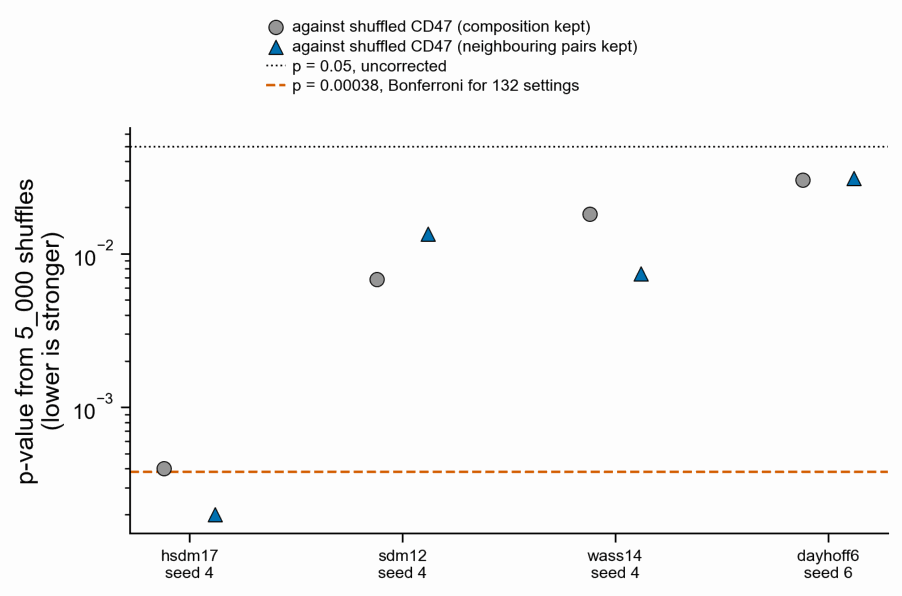

In [13]:
print("The four that beat the uncorrected threshold, re-tested with 5_000 shuffles")
print("of each kind. The Bonferroni threshold for 132 settings is p < 0.00038.")
print(
    follow.select(
        "alphabet",
        "n_classes",
        "seed_length",
        "penalty",
        "score",
        "segment_length",
        "p_composition_null",
        "p_neighbour_pairs_null",
        "survives_bonferroni_both_nulls",
    )
)
print(
    f"\nSurviving both nulls at the corrected threshold: "
    f"{follow.filter(pl.col('survives_bonferroni_both_nulls')).height} of {follow.height}"
)
show("276k_seed_extend_null_tests", aspect=0.65)

**Figure 276k.** Each candidate's p-value against both nulls, with the corrected threshold.
`figures/276k_seed_extend_null_tests.png`. The `hsdm17` hit lands on p = 0.0004 against the
composition null and 0.0002 against the stricter one, with the corrected threshold at
0.00038, so it misses on one null and clears it on the other. The other three are an order
of magnitude away. Nothing survives both.

Where each candidate's score actually comes from:
shape: (4, 9)
┌──────────┬─────────────┬─────────────┬────────────────┬───┬────────────┬───────────────────────┬────────────────────────┬─────────────────────┐
│ alphabet ┆ seed_length ┆ total_score ┆ segment_length ┆ … ┆ loop_score ┆ loop_score_per_column ┆ other_score_per_column ┆ loop_share_of_score │
│ ---      ┆ ---         ┆ ---         ┆ ---            ┆   ┆ ---        ┆ ---                   ┆ ---                    ┆ ---                 │
│ str      ┆ i64         ┆ f64         ┆ i64            ┆   ┆ f64        ┆ f64                   ┆ f64                    ┆ f64                 │
╞══════════╪═════════════╪═════════════╪════════════════╪═══╪════════════╪═══════════════════════╪════════════════════════╪═════════════════════╡
│ hsdm17   ┆ 4           ┆ 6.0         ┆ 36             ┆ … ┆ 1.0        ┆ 0.143                 ┆ 0.172                  ┆ 0.167               │
│ sdm12    ┆ 4           ┆ 6.5         ┆ 38             ┆ … 

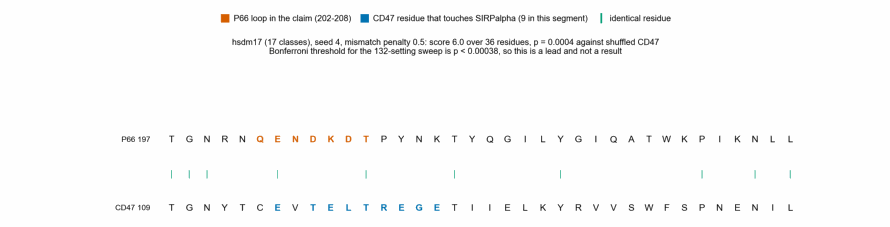

In [14]:
print("Where each candidate's score actually comes from:")
print(
    contrib.select(
        "alphabet",
        "seed_length",
        "total_score",
        "segment_length",
        "loop_columns",
        "loop_score",
        "loop_score_per_column",
        "other_score_per_column",
        "loop_share_of_score",
    )
)
print("\nWhat sits opposite the loop in each segment:")
print(
    contrib.select(
        "alphabet",
        "p66_loop_residues",
        "cd47_residues_opposite_loop",
        "n_face_residues_opposite_loop",
    )
)
worse = contrib.filter(
    pl.col("loop_score_per_column") < pl.col("other_score_per_column")
)
print(
    f"\nCandidates where the loop scores worse per column than the rest of its own "
    f"segment: {worse.height} of {contrib.height}"
)
show("276j_seed_extend_best_alignment", aspect=0.24)

**Figure 276j.** The strongest candidate written out residue by residue.
`figures/276j_seed_extend_best_alignment.png`. Vermillion is the P66 loop, blue is a CD47
residue that touches SIRPalpha, a green bar is an identical residue.

**What it says, and it is the closest thing in this notebook to support for the claim.**
`hsdm17` with a 4-class seed finds a 36-residue ungapped segment, P66 197-232 against CD47
109-144, which is 92% inside CD47's extracellular region but only 53% inside the
immunoglobulin domain itself (section 6m), and covers 9 of the 21 face residues
(115 and 117-124, the face's longest run). It covers the whole loop including both
aspartates, and opposite `QENDKDT` sits `CEVTELT`, 5 residues of which touch SIRPalpha.
`sdm12` finds the same segment, though section 6j shows the two are not independent of each
other. Both sides are stretches with charged residues, which is what the claim is about.

**Why it still is not support.** Four reasons, in order of how much they matter:

1. **The loop is the worst part of the segment.** Splitting the score column by column: the
   loop contributes 1.0 of `hsdm17`'s 6.0, at 0.143 per column against 0.172 for the rest
   of the same segment. In `dayhoff6` the loop contributes **-2.0**, so that segment scores
   well in spite of the loop. In 3 of the 4 candidates the loop scores worse per column than
   its own flanks. The alignment is carried by `TGN` against `TGN` at the start and
   `NIL` against `NLL` at the end, both outside the loop.
2. **Nothing survives its own multiplicity.** 4 of 132 settings beat p < 0.05, against 6.6
   expected by chance; and at the corrected threshold none clears both nulls.
3. **Only the most lenient penalty produces any of it.** All four candidates are at penalty
   0.5, the setting that elsewhere in the same sweep extends through entire proteins.
4. **The one candidate where the loop is the whole segment misses the face.** `wass14` puts
   `QENDKDT` against `NENILIV` with a score the loop fully earns, but that stretch of CD47
   touches no face residue at all.

**What would settle it.** The `hsdm17` segment is a real lead and is worth one dedicated
test rather than a sweep: fix the alphabet, seed length and penalty in advance, and ask
whether a segment like it appears for the claimed pair more often than for P66 against a
set of human proteins matched on length and acidic content. That is a different experiment
from this notebook, and it is the one that would turn p = 0.0004 at setting 1 of 132 into a
number worth quoting.

## 6d. The prespecified test of the hsdm17 lead

Section 6c left one lead: `hsdm17`, seed 4, penalty 0.5 puts a 36-residue segment across
the loop and onto 9 residues of CD47's SIRPalpha face at p = 0.0004 against shuffled CD47.
That number is not quotable, for two reasons. It is the best of 132 tries. And shuffling
CD47 destroys the protein, so almost any real protein beats that null.

This is the test that makes the lead quotable or kills it. Everything is fixed before it
runs, and nothing is swept:

| | |
|---|---|
| alphabet, seed length, mismatch penalty, X-drop | `hsdm17`, 4, 0.5, 10 |
| statistic | the score of the best segment whose P66 side covers any of 202-208 |
| null | real human proteins matched to CD47 on length (within 10%) and on acidic fraction (within 1.5 points of 7.7% D+E), which is what the loop is made of |
| p | the share of matched proteins scoring at least as high |
| decision | the lead survives only if p < 0.05 |

A second statistic, also fixed in advance: the share reaching that score with a segment at
least as long as CD47's 36 residues.

One bug worth recording, because it would have produced the answer the test was looking
for. GENCODE translation headers put the transcript name in field 5 and the gene symbol in
field 6. Reading field 5 let CD47's own transcript into the background as `CD47-202`, and
it came back as the one protein matching CD47's score. Reading field 6, and also dropping
anything whose sequence is CD47's, removes it.

shape: (15, 2)
┌─────────────────────────────────┬────────┐
│ column                          ┆ value  │
│ ---                             ┆ ---    │
│ str                             ┆ str    │
╞═════════════════════════════════╪════════╡
│ alphabet                        ┆ hsdm17 │
│ seed_length                     ┆ 4      │
│ penalty                         ┆ 0.5    │
│ observed_score                  ┆ 6.0    │
│ observed_segment_length         ┆ 36     │
│ n_background                    ┆ 437    │
│ background_reaching_loop        ┆ 12     │
│ background_median_score         ┆ 0.0    │
│ background_max_score            ┆ 5.5    │
│ n_background_score_ge_observed  ┆ 0      │
│ p_primary                       ┆ 0.0    │
│ n_background_score_and_length_… ┆ 0      │
│ p_secondary                     ┆ 0.0    │
│ alpha                           ┆ 0.05   │
│ lead_survives                   ┆ true   │
└─────────────────────────────────┴────────┘

Background: 437 matched human proteins,

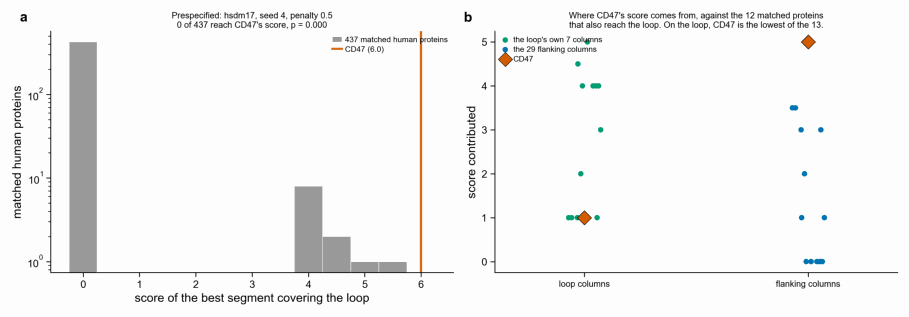

In [15]:
prespec = pl.read_csv(DATA / "16_hsdm17_prespecified_result.csv")
bg = pl.read_csv(DATA / "15_hsdm17_prespecified_background.csv")
print(prespec.transpose(include_header=True, column_names=["value"]))
print(
    f"\nBackground: {bg.height} matched human proteins, "
    f"{bg['reaches_loop'].sum()} of which produce a loop-covering segment at all."
)
print(
    f"  score median {bg['score'].median()}, max {bg['score'].max()}; "
    f"CD47 is {prespec['observed_score'][0]}"
)
print("\nThe strongest matched proteins:")
print(
    bg.sort("score", descending=True)
    .select("gene", "length", "acidic_fraction", "score", "segment_length")
    .head(8)
)
show("276l_hsdm17_prespecified_test", aspect=0.34)

**Figure 276l panel a** is this result; panel b belongs to the next section.

**The lead survives its prespecified test.** 0 of 437 length- and acid-matched human
proteins reach CD47's score of 6.0. The observed background fraction is 0/437,
which passes the fixed 0.05 rule. Zero observed exceedances do not establish
p < 0.002; one background protein would change the fraction by 1/437 = 0.00229. Only 12 of the 437 produce a segment covering the loop at all; the median score
is 0 and the best is 5.5. On the statistic fixed in advance, CD47 is the single best match
P66's loop region has among 437 proteins of its own length and acidity.

That is the first thing anywhere in this notebook that points toward the claim rather than
away from it, and it is worth saying plainly before the next section takes most of it back.

## 6e. What that passing test is actually evidence about

The score it passed on is the whole 36-residue segment, and section 6c already showed the
loop contributes 1.0 of it while scoring worse per column than its own flanks. So the test
may have passed for the window P66 197-232 rather than for the loop the claim names. The
way to tell is to split the same background by column.

**These two numbers are post-hoc.** They were computed after seeing the prespecified result
and are reported as what the result means, not as a second claim.

shape: (2, 8)
┌───────────────────────┬──────────┬─────────────────────────────────┬──────────────┬────────────────┬─────────────────────────────────┬────────────┬──────────────────┐
│ statistic             ┆ observed ┆ n_background_ge_counting_non_r… ┆ n_background ┆ p_counting_all ┆ n_background_ge_among_those_re… ┆ n_reaching ┆ p_among_reaching │
│ ---                   ┆ ---      ┆ ---                             ┆ ---          ┆ ---            ┆ ---                             ┆ ---        ┆ ---              │
│ str                   ┆ f64      ┆ i64                             ┆ i64          ┆ f64            ┆ i64                             ┆ i64        ┆ f64              │
╞═══════════════════════╪══════════╪═════════════════════════════════╪══════════════╪════════════════╪═════════════════════════════════╪════════════╪══════════════════╡
│ loop columns only     ┆ 1.0      ┆ 12                              ┆ 437          ┆ 0.02746        ┆ 12                              ┆ 12  

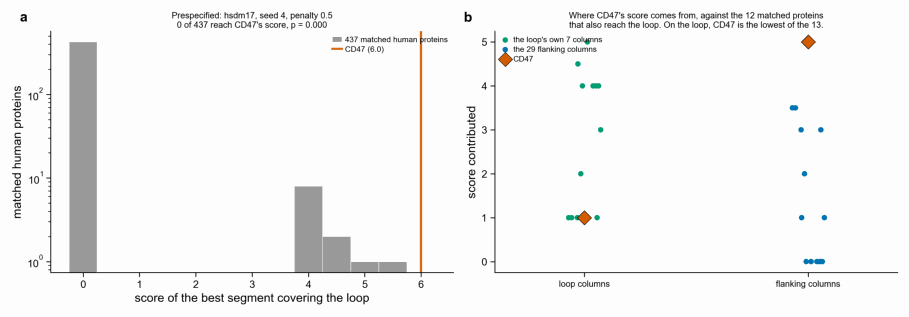

In [16]:
split = pl.read_csv(DATA / "18_hsdm17_loop_vs_flanks_result.csv")
split_bg = pl.read_csv(DATA / "17_hsdm17_loop_vs_flanks_background.csv")
reached = split_bg.filter(pl.col("reaches_loop"))
print(split)
print(f"\n{reached.height} of {split_bg.height} matched proteins reach the loop.")
print(
    f"Loop columns:  CD47 {split.filter(pl.col('statistic') == 'loop columns only')['observed'][0]}, "
    f"background median {reached['loop_score'].median()}, max {reached['loop_score'].max()}"
)
print(
    f"Flank columns: CD47 {split.filter(pl.col('statistic') == 'flanking columns only')['observed'][0]}, "
    f"background median {reached['flank_score'].median()}, max {reached['flank_score'].max()}"
)
show("276l_hsdm17_prespecified_test", aspect=0.34)

**Figure 276l.** The prespecified test and what it is about.
`figures/276l_hsdm17_prespecified_test.png`. Panel **a**: CD47 against the 437 matched
proteins on the prespecified statistic. Panel **b**: the same 36 columns split into the
loop's 7 and the flanking 29, for CD47 and for the 12 matched proteins that also reach the
loop.

**The passing test is about the flanks, not the loop.** On the 29 flanking columns CD47
scores 5.0 and no matched protein reaches it, median 1.0. On the loop's own 7 columns CD47
scores 1.0 against a background median of 3.5 and a maximum of 5.0: **all 12 matched
proteins that reach the loop beat CD47 there.** CD47 is the lowest of the thirteen on the
part of the segment the claim is about, and the highest of 438 on the part it is not.

So the honest reading, in one sentence: P66 197-232 has a local similarity to CD47 109-144
that no length- and acidity-matched human protein matches, and the loop at 202-208 is the
weakest seven columns of it. That is a real and specific sequence similarity, and it is not
evidence for the loop being a CD47 mimic. If anything it is evidence against, because a
convergent functional mimic should be strongest where the function is.

What it might be instead is a question this notebook cannot answer: a 36-residue ungapped
similarity between a bacterial barrel and an immunoglobulin domain, 53% inside the
ectodomain and overlapping the face's longest run, is worth someone looking at on its own
terms rather than as support for this claim.

## 6f. Every alphabet in one table

The results above are spread over several tests. This is one row per alphabet, so every
alphabet can be read at once. The eight that write the loop as one repeated class were left
out of the 132-setting sweep, because at penalty 0.5 a seed there matches every polar
stretch and the run does not finish; they are run here at penalties 1.0 and 2.0, where
extension dies fast enough to be tractable, so the table has no blanks.

Exact k-mers covering the loop, per alphabet:
shape: (19, 10)
┌──────────────────────────┬───────────┬───────────────────┬────────────────────────────┬───┬─────────────┬───────────────┬────────────────┬──────────────────────┐
│ alphabet                 ┆ n_classes ┆ loop_class_string ┆ n_distinct_classes_in_loop ┆ … ┆ best_pair_k ┆ best_pair_p66 ┆ best_pair_cd47 ┆ best_pair_identities │
│ ---                      ┆ ---       ┆ ---               ┆ ---                        ┆   ┆ ---         ┆ ---           ┆ ---            ┆ ---                  │
│ str                      ┆ i64       ┆ str               ┆ i64                        ┆   ┆ i64         ┆ str           ┆ str            ┆ i64                  │
╞══════════════════════════╪═══════════╪═══════════════════╪════════════════════════════╪═══╪═════════════╪═══════════════╪════════════════╪══════════════════════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ BBBBBBB           ┆ 1                          ┆ … ┆ 5           ┆ NRNQE     

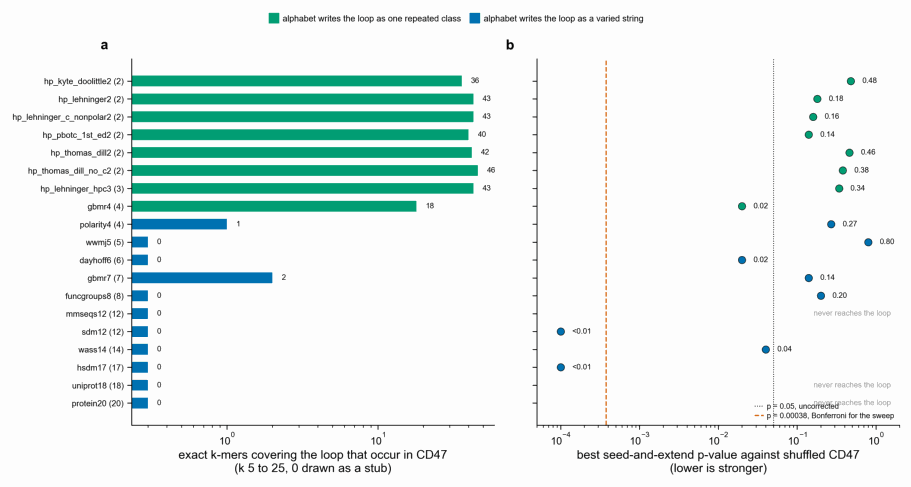

In [17]:
summary = pl.read_csv(DATA / "20_all_alphabets_summary.csv")
print("Exact k-mers covering the loop, per alphabet:")
print(
    summary.select(
        "alphabet",
        "n_classes",
        "loop_class_string",
        "n_distinct_classes_in_loop",
        "loop_kmers_in_cd47",
        "highest_k_with_a_loop_kmer",
        "best_pair_k",
        "best_pair_p66",
        "best_pair_cd47",
        "best_pair_identities",
    )
)
print("\nSeed-and-extend on the loop, per alphabet:")
print(
    summary.select(
        "alphabet",
        "n_classes",
        "loop_is_one_repeated_class",
        "seed_extend_settings_reaching_loop",
        "seed_extend_best_score",
        "seed_extend_best_p",
        "max_face_residues_hit",
    )
)
print(
    f"\nAlphabets with any exact loop k-mer in CD47: "
    f"{(summary['loop_kmers_in_cd47'] > 0).sum()} of {summary.height}"
)
print(
    f"Alphabets where seed-and-extend reaches the loop at some setting: "
    f"{(summary['seed_extend_settings_reaching_loop'] > 0).sum()} of {summary.height}"
)
show("276m_all_alphabets_summary", aspect=0.56)

**Figure 276m.** Every alphabet, exact k-mers on the left and seed-and-extend on the right.
`figures/276m_all_alphabets_summary.png`. Green is an alphabet that writes the loop as one
repeated class, blue is one that writes it as a varied string.

**How to read the table.**

* **Exact k-mers reach the loop in 10 of 19 alphabets**, and 8 of those 10 are the ones
  that cannot tell the loop from any polar stretch. The two that are not are `polarity4`
  (1 k-mer, k = 5) and `gbmr7` (2, k = 5). `funcgroups8`, `mmseqs12`, `sdm12`, `wass14`,
  `hsdm17`, `uniprot18`, `protein20`, `wwmj5` and `dayhoff6` have none at any k from 5 to 25.
* **Seed-and-extend reaches the loop in 16 of 19.** Only `mmseqs12`, `uniprot18` and
  `protein20` never do, which is what the three largest alphabets should do.
* **The big scores are the uninformative ones.** The two- and three-class alphabets reach
  scores of 50 to 61 and sit at p = 0.14 to 0.48 against shuffled CD47: entirely ordinary.
  `gbmr7` and `polarity4` touch all 21 face residues, with segments of 250 residues and
  more, which is the extension running through the protein rather than a match.
* **The only two alphabets that get anywhere near the corrected threshold are `sdm12` and
  `hsdm17`**, both 12 or more classes, both finding the same 36-residue segment, and
  section 6e shows what that segment is and is not.

## 6g. What the 36-residue similarity is

The prespecified test said the segment is specific and the column split said the loop is
its weakest part. Neither says what it is. Four questions, each with its own comparison.

```
P66 197-232  TGNRNQENDKDTPYNKTYQGILYGIQATWKPIKNLL
             |||   |    |    |     |       |  | |
CD47 109-144 TGNYTCEVTELTREGETIIELKYRVVSWFSPNENIL
```

10 identical of 36, 28%, which is ordinary twilight-zone territory. The anchor is `TGN`
against `TGN` at the start and `N.L` against `N.L` at the end.

Composition of the two halves against their own proteins:
shape: (2, 9)
┌──────────────┬────────┬───────────────────┬──────────────────┬───┬──────────────────────────────┬─────────────────────┬────────────────────────────┬────────────────────┐
│ which        ┆ length ┆ acidic_DE_percent ┆ basic_KR_percent ┆ … ┆ whole_protein_acidic_percent ┆ n_distinct_residues ┆ longest_single_residue_run ┆ most_common        │
│ ---          ┆ ---    ┆ ---               ┆ ---              ┆   ┆ ---                          ┆ ---                 ┆ ---                        ┆ ---                │
│ str          ┆ i64    ┆ f64               ┆ f64              ┆   ┆ f64                          ┆ i64                 ┆ i64                        ┆ str                │
╞══════════════╪════════╪═══════════════════╪══════════════════╪═══╪══════════════════════════════╪═════════════════════╪════════════════════════════╪════════════════════╡
│ P66 197-232  ┆ 36     ┆ 8.3               ┆ 13.9             ┆ … ┆

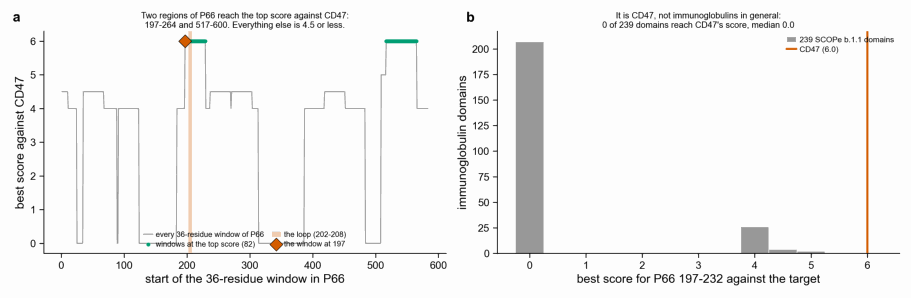

In [18]:
char = pl.read_csv(DATA / "24_segment_characterisation.csv")
comp = pl.read_csv(DATA / "21_segment_composition.csv")
windows = pl.read_csv(DATA / "23_p66_windows_vs_cd47.csv")
ig = pl.read_csv(DATA / "22_segment_vs_ig_domains.csv")
ss = pl.read_csv(DATA / "07_p66_secondary_structure.csv")

print("Composition of the two halves against their own proteins:")
print(comp.drop("sequence"))
print("\nSecondary structure, P66 from its own model (mean pLDDT 29, so indicative):")
seg_ss = ss.filter(pl.col("full_position").is_between(197, 232))
print(
    "P66 197-232: "
    + "".join(
        "E" if s == "strand" else "H" if s == "helix" else "-"
        for s in seg_ss["secondary_structure"]
    )
)
print("\nSpecificity:")
print(char.transpose(include_header=True, column_names=["value"]))
top = windows.filter(pl.col("best_score") == windows["best_score"].max())[
    "p66_start"
].to_list()
runs = []
for p in sorted(top):
    if runs and p == runs[-1][-1] + 1:
        runs[-1].append(p)
    else:
        runs.append([p])
print(
    f"\n{len(top)} of {windows.height} P66 windows reach the top score, in "
    f"{len(runs)} distinct regions:"
)
for r in runs:
    print(f"  P66 {r[0]}-{r[-1] + 35}")
show("276n_segment_specificity", aspect=0.33)

**Figure 276n.** The segment's specificity. `figures/276n_segment_specificity.png`.

**1. What they are structurally.** P66 197-232 is strand, coil, strand: 18 residues of
β-strand and 18 of coil, which is what an extracellular turn between two strands of a
β-barrel looks like, and the loop sits in the coil. CD47 109-144 is the last two strands
of the immunoglobulin domain plus the first turn of the transmembrane helix (15 strand, 14
coil, 7 helix). So both sides are strand-turn-strand, which is the commonest thing in
either protein, and the P66 side comes from a model whose mean pLDDT is 29.

**2. It is not a compositional artefact, but the two sides are not compositionally alike
either.** CD47 109-144 is 16.7% acidic against 7.7% for the whole of CD47, so it is a real
acidic patch. P66 197-232 is 8.3% acidic against 11.2% for the whole of P66, so it is
slightly *less* acidic than its own protein, and it is basic-leaning at 13.9% K+R. Neither
side is low-complexity: 14 and 15 distinct residues, longest single-residue run 2.

**3. It is CD47, not immunoglobulins in general.** P66 197-232 scores 6.0 against CD47 and
**0 of 239** SCOPe b.1.1 immunoglobulin domains reach that, median 0.0, best 5.0. So P66
197-232 does not simply like the immunoglobulin fold.

**4. Two regions of P66 reach this score against CD47, not one.** Of 583 36-residue
windows, 82 tie at the top, and those 82 fall into exactly two stretches: **197-264**, the
one found here, and **517-600**, which no test in this notebook has looked at. Everything
else in P66 scores 4.5 or less. So the window is one of two, not unique.

Put together: a strand-turn-strand of a bacterial outer-membrane barrel that resembles the
last strands of CD47's immunoglobulin domain more than 239 other immunoglobulin domains do,
at 28% identity, with its own loop as the weakest part. That is a specific local similarity
with no function attached to it by anything measured here.

## 6h. Combining alphabets, and why it did worse

The idea is that if one alphabet finds a match, another should corroborate it, so a
combination should beat either alone. Two combinations were fixed in advance, and only two:
`polarity4` + `funcgroups8`, and all 19 alphabets. Each was scored by how many of its
alphabets put the two residues in the same class, mapped to +1 when all agree and -1 when
none do, with the seed required to match in every alphabet at once.

It did worse, on both, at every seed length.

shape: (12, 18)
┌─────────────────────────┬─────────────┬──────────────┬─────────────┬───┬──────────┬─────────────────────────┬───────────────────────┬────────────────────────┐
│ combination             ┆ n_alphabets ┆ seeding_rule ┆ seed_length ┆ … ┆ p_total  ┆ n_background_ge_on_loop ┆ p_loop_among_reaching ┆ background_loop_median │
│ ---                     ┆ ---         ┆ ---          ┆ ---         ┆   ┆ ---      ┆ ---                     ┆ ---                   ┆ ---                    │
│ str                     ┆ i64         ┆ str          ┆ i64         ┆   ┆ f64      ┆ i64                     ┆ f64                   ┆ f64                    │
╞═════════════════════════╪═════════════╪══════════════╪═════════════╪═══╪══════════╪═════════════════════════╪═══════════════════════╪════════════════════════╡
│ polarity4 + funcgroups8 ┆ 2           ┆ product      ┆ 4           ┆ … ┆ null     ┆ null                    ┆ null                  ┆ null                   │
│ polarity4 + func

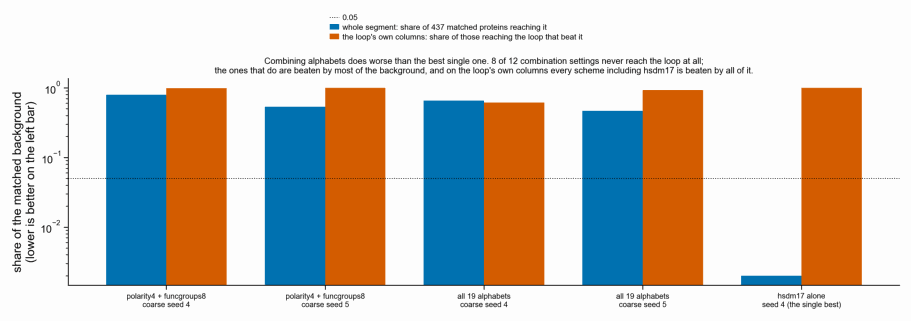

In [19]:
combined = pl.read_csv(DATA / "25_combined_alphabets.csv")
print(
    combined.select(
        [
            c
            for c in combined.columns
            if c not in ("p66_span", "cd47_span", "product_classes")
        ]
    )
)
print(
    f"\nSettings that never reach the loop: "
    f"{combined.filter(~pl.col('reaches_loop')).height} of {combined.height}"
)
print("Product alphabet sizes:")
print(
    combined.group_by("combination", "n_alphabets", "product_classes")
    .len()
    .sort("n_alphabets")
)
show("276o_combined_alphabets", aspect=0.35)

**Figure 276o.** Both combinations against the best single alphabet.
`figures/276o_combined_alphabets.png`.

**Product seeding fails outright.** Requiring every alphabet in the combination to agree on
the seed means intersecting them, and the intersection of all 19 has **20 classes over the
20 residues**: requiring every alphabet to agree is requiring identity. No 4-residue
identity exists between P66's loop region and CD47, so the loop is never reached. For
`polarity4` + `funcgroups8` the product has 11 classes, and it is reached no better.

**Coarse seeding reaches the loop and is beaten by the background.** Letting `polarity4`
propose seeds and the combination score the extension, the best loop-covering segment is 5
to 7 residues with a score of 1.6 to 3.0, and 47% to 80% of the 437 matched human proteins
reach it. On the loop's own columns, 427 of 433 matched proteins beat `polarity4` +
`funcgroups8`. Compare the best single alphabet: `hsdm17` alone, 36 residues, score 6.0,
beaten by 0 of 437.

## 6i. Why averaging hurt, when corroboration should help

The intuition is right and the implementation was wrong. Three measurements say where.

1. How often each alphabet calls a random pair of residues a match:
shape: (19, 3)
┌──────────────────────────┬───────────┬─────────────────────────────────┐
│ alphabet                 ┆ n_classes ┆ chance_two_residues_share_a_cl… │
│ ---                      ┆ ---       ┆ ---                             │
│ str                      ┆ i64       ┆ f64                             │
╞══════════════════════════╪═══════════╪═════════════════════════════════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ 0.545                           │
│ hp_lehninger2            ┆ 2         ┆ 0.5                             │
│ hp_lehninger_c_nonpolar2 ┆ 2         ┆ 0.505                           │
│ hp_pbotc_1st_ed2         ┆ 2         ┆ 0.5                             │
│ hp_thomas_dill2          ┆ 2         ┆ 0.505                           │
│ hp_thomas_dill_no_c2     ┆ 2         ┆ 0.52                            │
│ hp_lehninger_hpc3        ┆ 3         ┆ 0.455                           │
│ gbmr4          

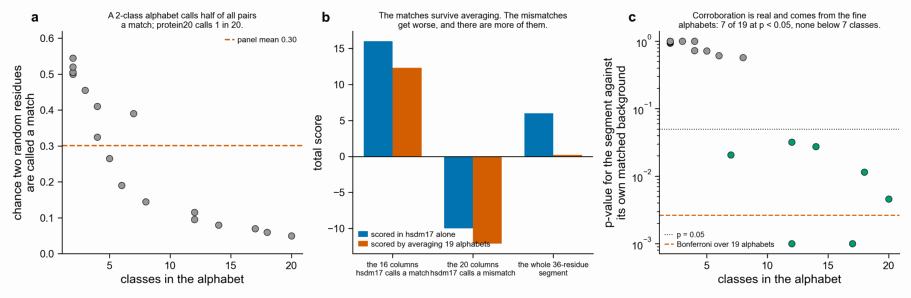

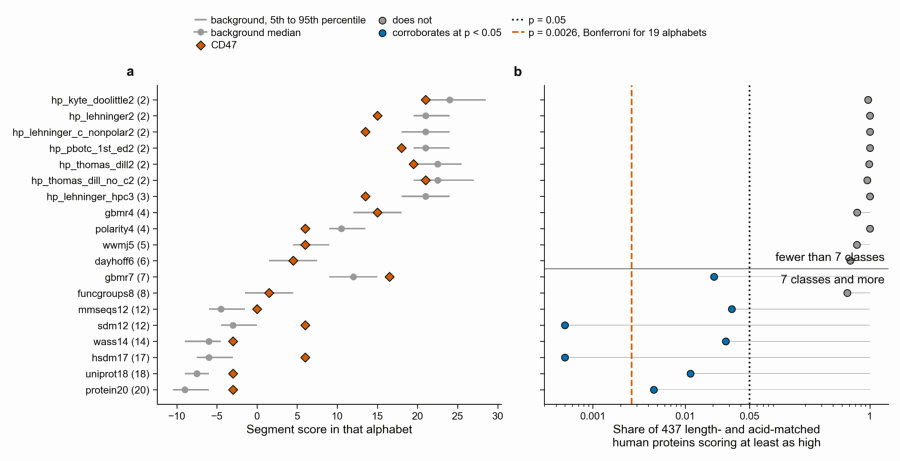

In [20]:
coll = pl.read_csv(DATA / "26_alphabet_collision_rates.csv")
cols = pl.read_csv(DATA / "27_segment_columns_one_vs_average.csv")
corr = pl.read_csv(DATA / "28_segment_corroboration_by_alphabet.csv")

print("1. How often each alphabet calls a random pair of residues a match:")
print(coll)
print(f"   panel mean {coll['chance_two_residues_share_a_class'].mean():.3f}")
matched = cols.filter(pl.col("hsdm17_column_score") > 0)
mismatched = cols.filter(pl.col("hsdm17_column_score") < 0)
print(f"\n2. The segment's 36 columns, scored both ways:")
print(
    f"   {matched.height} columns hsdm17 calls a match:    "
    f"hsdm17 {matched['hsdm17_column_score'].sum():+.1f}, "
    f"averaged {matched['averaged_column_score'].sum():+.2f}  "
    f"(mean share agreeing {matched['share_of_19_alphabets_agreeing'].mean():.2f})"
)
print(
    f"   {mismatched.height} columns hsdm17 calls a mismatch: "
    f"hsdm17 {mismatched['hsdm17_column_score'].sum():+.1f}, "
    f"averaged {mismatched['averaged_column_score'].sum():+.2f}  "
    f"(mean share agreeing {mismatched['share_of_19_alphabets_agreeing'].mean():.2f})"
)
print(
    f"   whole segment:                          "
    f"hsdm17 {cols['hsdm17_column_score'].sum():+.1f}, "
    f"averaged {cols['averaged_column_score'].sum():+.2f}"
)
print("\n3. Each alphabet asked on its own whether the segment beats its own")
print("   matched background (corroboration as a conjunction, not an average):")
print(
    corr.select(
        "alphabet",
        "n_classes",
        "segment_score_on_cd47",
        "background_median",
        "n_background_ge",
        "p_value",
        "corroborates_at_0_05",
    )
)
print(
    f"\n   {corr['corroborates_at_0_05'].sum()} of {corr.height} corroborate at "
    f"p < 0.05; {(corr['p_value'] < 0.05 / corr.height).sum()} clear Bonferroni "
    f"({0.05 / corr.height:.4f})."
)
show("276p_why_combining_alphabets_hurts", aspect=0.32)
show("276q_segment_corroboration_by_alphabet", aspect=0.5)

**Figure 276p.** Why averaging hurt, and where corroboration does happen.
`figures/276p_why_combining_alphabets_hurts.png`.

**The matches were corroborated. The mismatches were corroborated too, and that is what
killed it.** Of the 36 columns, the 16 that `hsdm17` calls a match are agreed on by 88% of
the 19 alphabets, so averaging costs them almost nothing: +16.0 becomes +12.3. The 20 that
`hsdm17` calls a mismatch are agreed on by only 20%, so under the averaged score they are
worth -12.1 where `hsdm17`, at a mismatch penalty of 0.5, charged only -10.0. The averaged
scheme charges up to -1 for a mismatch and `hsdm17` charged -0.5, and the segment is 56%
mismatch, so the whole thing falls from **6.0 to 0.21** and no X-drop extension can build
it. That is the 5-to-7-residue segments in 6h, in one number.

So averaging did not dilute the signal. It raised the price of the noise. The fix is not to
abandon combining but to stop tying the mismatch penalty to the agreement scale: score a
column as the share agreeing minus a penalty chosen independently, the way a substitution
matrix separates its positive and negative entries.

**And the alphabets do not disagree at random: they disagree because they differ in size.**
A 2-class alphabet calls 54% of all residue pairs a match and `protein20` calls 5%, with a
panel mean of 0.30. An unweighted average over alphabets spanning 2 to 20 classes is
therefore set mostly by how many coarse members the panel has, not by whether the residues
resemble each other. 12 of the 19 alphabets here have 8 classes or fewer.

**Corroboration done as a conjunction works, and it says something useful.** Asking each
alphabet on its own whether the fixed segment beats its own matched background, **7 of 19
corroborate at p < 0.05** and 2 clear Bonferroni: `hsdm17` and `sdm12`, both at p = 0.000.
The split is by alphabet size and it is sharp: **7 of the 8 alphabets with 7 or more classes
corroborate, and 0 of the 11 with fewer than 7 do.** `funcgroups8` is the one exception on
the fine side, at p = 0.57. On the coarse side nothing comes close, p = 0.61 to 1.00, and
for `polarity4`, `hp_lehninger2`, `hp_lehninger_c_nonpolar2`, `hp_lehninger_hpc3` and
`hp_pbotc_1st_ed2` the p-value is exactly 1.00: every single one of the 437 matched proteins
beats CD47 under those alphabets.

**Figure 276q.** The same test, alphabet by alphabet.
`figures/276q_segment_corroboration_by_alphabet.png`. Panel **a** is in each alphabet's own
units, because the scores are not comparable between them, and that is the point: in a
two-letter alphabet CD47 scores 21 and still sits below the background's median of 24,
while in `hsdm17` it scores 6.0 against a background whose 95th percentile is below 0.
Panel **b** is the one number per alphabet, with the line drawn where the result puts it.

That is the practical lesson for kmerseek, and it is about method rather than about P66. For
a 36-residue similarity at 28% identity, the discriminating alphabets are the ones with 12
to 20 classes; every alphabet below 7 classes is blind to it, and a panel average dominated
by them is blind for the same reason. The HP family's case has to rest on
something other than segments like this one.

## 6j. Why funcgroups8 fails at 8 classes, and whether the corroboration is independent

`funcgroups8` has 8 classes, more than `dayhoff6` or `gbmr7`, and calls a random pair of
residues a match only 14.5% of the time, which is rarer than `dayhoff6` at 19%. By both of
those measures it should do well, and it sits at p = 0.57. Class count is not what decides
this, and neither is the chance rate on its own. What decides it is whether an alphabet
happens to merge the particular residue pairs this segment contains.

Matched columns against what chance gives, per alphabet:
shape: (19, 10)
┌──────────────────────────┬───────────┬──────────────────────────────┬────────────────────────┬───┬────────────────────────┬───────────────────────────────┬──────────┬──────────────────────┐
│ alphabet                 ┆ n_classes ┆ chance_a_random_pair_matches ┆ columns_called_a_match ┆ … ┆ of_those_non_identical ┆ of_those_acidic_against_basic ┆ p_value  ┆ corroborates_at_0_05 │
│ ---                      ┆ ---       ┆ ---                          ┆ ---                    ┆   ┆ ---                    ┆ ---                           ┆ ---      ┆ ---                  │
│ str                      ┆ i64       ┆ f64                          ┆ i64                    ┆   ┆ i64                    ┆ i64                           ┆ f64      ┆ bool                 │
╞══════════════════════════╪═══════════╪══════════════════════════════╪════════════════════════╪═══╪════════════════════════╪═══════════════════════════════╪══

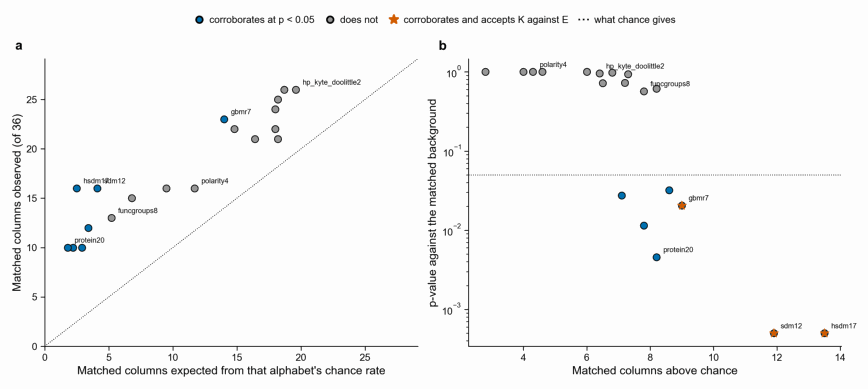

In [21]:
merges = pl.read_csv(DATA / "30_segment_merges_by_alphabet.csv")
pairs = pl.read_csv(DATA / "31_segment_matched_pairs_by_alphabet.csv")
print("Matched columns against what chance gives, per alphabet:")
print(
    merges.select(
        "alphabet",
        "n_classes",
        "chance_a_random_pair_matches",
        "columns_called_a_match",
        "expected_by_chance",
        "excess_over_chance",
        "of_those_non_identical",
        "of_those_acidic_against_basic",
        "p_value",
        "corroborates_at_0_05",
    )
)
print("\nThe non-identical pairs each alphabet accepts in this segment:")
for name in ("funcgroups8", "sdm12", "hsdm17", "protein20", "gbmr7"):
    sub = pairs.filter((pl.col("alphabet") == name) & ~pl.col("identical"))
    print(f"  {name:12} {', '.join(sub['pair'].to_list()) or 'none'}")
sdm12 = set(
    pairs.filter((pl.col("alphabet") == "sdm12") & ~pl.col("identical"))["pair"]
)
hsdm17 = set(
    pairs.filter((pl.col("alphabet") == "hsdm17") & ~pl.col("identical"))["pair"]
)
print(
    f"\nsdm12 and hsdm17 share {len(sdm12 & hsdm17)} of "
    f"{len(sdm12 | hsdm17)} non-identical pairs: {', '.join(sorted(sdm12 & hsdm17))}"
)
show("276r_which_merges_carry_the_segment", aspect=0.42)

**Figure 276r.** What each alphabet gains over chance on this segment, and which merges
give it. `figures/276r_which_merges_carry_the_segment.png`.

**Why `funcgroups8` fails.** The segment has 10 identical columns. On top of those,
`funcgroups8` accepts only three non-identical pairs, all of them `I` against `L` or `V`:
13 matched columns against 5.2 expected. `sdm12` and `hsdm17` accept the same I/L/V pairs
*and* `K` against `E`, which adds three more columns: 16 against 4.1 and 16 against 2.5.
So `funcgroups8` fails for the most ordinary reason in biochemistry: it keeps `DE` and `KR`
in separate classes, as a functional-group alphabet should, and the signal in this segment
is three columns of a P66 lysine against a CD47 glutamate.

That is also worth saying the other way round. The segment pairs P66's basic residues
against CD47's acidic ones, which is what section 6g found compositionally: P66 197-232 is
13.9% K+R and CD47 109-144 is 16.7% D+E. An alphabet only sees that as similarity if it
merges a basic residue with an acidic one, which is not a thing most alphabets do.

**And the two alphabets that cleared Bonferroni are not independent.** `sdm12` and `hsdm17`
accept **exactly the same four** non-identical pairs: `I-L`, `I-V`, `L-I` and `K-E`. They
are the same 16 columns, scored twice. Both come from the same paper, Prlic et al. 2000,
which is where the `KE` and `KER` merges come from. So "2 of 19 clear Bonferroni" is one
piece of evidence counted twice, not two.

**There is a second, cleaner line of evidence, and it needs no reduced alphabet at all.**
`protein20`, `uniprot18` and `wass14` corroborate the segment while accepting **zero**
non-identical pairs: they are scoring the 10 identical residues alone, against a chance rate
of 5 to 8%, so 10 identities where about 2 are expected. `protein20` reaches p = 0.005 that
way. That line does not depend on any alphabet's choices, and it is the one worth carrying
forward: **the segment has 10 identical residues in 36 columns where chance gives about 2,
and 435 of 437 matched human proteins do no better.**

## 6k. Would an E-value, an enrichment or a TF-IDF weighting see any of this better?

Every score so far counts a matched column as +1 whatever it is. kmerseek's own values do
not: it ranks by E-value, by enrichment and by summed inverse document frequency, so a rare
k-mer counts for more than a common one. Three answers, and the third one explains
everything above it.

**Enrichment is already here under another name.** Observed matched columns against the
columns chance gives is observed over expected, which is what section 6j prints. For the
segment it runs from 1.3x in `hp_kyte_doolittle2` to 6.4x in `hsdm17`.

**An E-value would add nothing.** A Karlin-Altschul E-value is a parametric stand-in for a
null, and this notebook already has the null empirically: 437 real human proteins matched to
CD47 on length and acidic fraction. Fitting a distribution to approximate a null that has
been measured can only lose accuracy, and this project has twice refused a KA fit on data
this thin. So the empirical p-value is used and the E-value is not computed.

**TF-IDF is the one that could have changed the answer, and it cannot, for a reason that
turns out to be the deepest thing in this notebook.**

Three metrics on the segment, 5-mers, corpus = 19_705 canonical human proteins:
shape: (6, 10)
┌──────────────────┬───────────┬─────────────────────────────────┬─────────────────────┬───┬────────────────────┬───────────────────────────┬────────────────────┬──────────────────────┐
│ alphabet         ┆ n_classes ┆ enrichment_observed_matched_co… ┆ enrichment_expected ┆ … ┆ summed_idf_on_cd47 ┆ background_max_summed_idf ┆ unweighted_p_value ┆ idf_weighted_p_value │
│ ---              ┆ ---       ┆ ---                             ┆ ---                 ┆   ┆ ---                ┆ ---                       ┆ ---                ┆ ---                  │
│ str              ┆ i64       ┆ i64                             ┆ f64                 ┆   ┆ f64                ┆ f64                       ┆ f64                ┆ f64                  │
╞══════════════════╪═══════════╪═════════════════════════════════╪═════════════════════╪═══╪════════════════════╪═══════════════════════════╪════════════════════

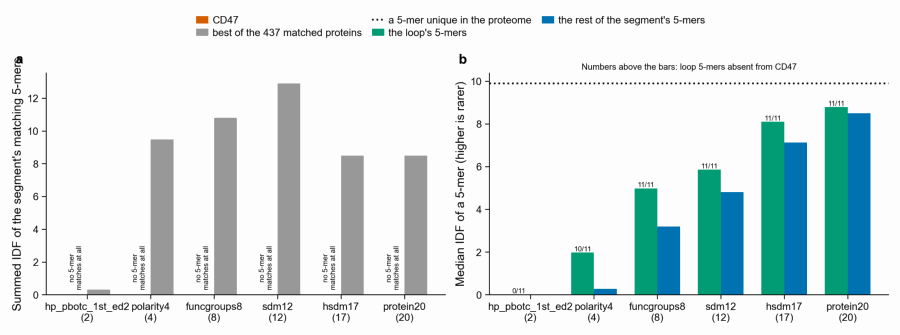

In [22]:
idf_seg = pl.read_csv(DATA / "32_idf_weighted_segment.csv")
idf_loop = pl.read_csv(DATA / "33_loop_kmer_idf.csv")
print("Three metrics on the segment, 5-mers, corpus = 19_705 canonical human proteins:")
print(
    idf_seg.select(
        "alphabet",
        "n_classes",
        "enrichment_observed_matched_columns",
        "enrichment_expected",
        "enrichment_ratio",
        "n_matched_kmers_in_segment",
        "summed_idf_on_cd47",
        "background_max_summed_idf",
        "unweighted_p_value",
        "idf_weighted_p_value",
    )
)
print("\nHow rare the loop's own 5-mers are, and how many are in CD47 at all:")
print(idf_loop)
show("276s_idf_weighting", aspect=0.36)

**Figure 276s.** What an IDF weighting does. `figures/276s_idf_weighting.png`.

**The segment contains no exactly matching 5-mer, in any alphabet.** Its 10 identities are
scattered: written as a match-mismatch string, the longest run of consecutive matching
columns is 3 in `protein20`, 4 in `hsdm17` and `sdm12`, and still only 4 in the two-letter
`hp_pbotc_1st_ed2` even though 24 of its 36 columns match.

```
protein20          111000100001000010000010000000100101   10/36, longest run 3
hsdm17             111000100101000110001010100000101111   16/36, longest run 4
hp_pbotc_1st_ed2   111010101101001111011011100011101111   24/36, longest run 4
```

So the summed IDF of the segment's matching 5-mers is **0.00 in all six alphabets tested**,
against a matched background that slides to any offset and reaches 0.31 to 12.9. The
IDF-weighted p-value is **1.00 everywhere**, and IDF weighting flips `protein20`, `hsdm17`
and `sdm12` from corroborating to not.

**Why that is the deepest point here, not a technicality.** IDF reweights a k-mer that exact
matching already found. It is a ranking metric, not a detecting one. With no matched k-mer
there is nothing to weight, and no weighting scheme, however clever, can recover a match
that was never made. The same goes for the E-value and the enrichment: all three are ways of
scoring hits, and the problem on this pair is that at k of 5 or more there are no hits.

This also explains two things that were left unexplained earlier:

* **Why seed-and-extend worked only at seed length 4.** The longest run of matching columns
  in the segment is 4. A seed of 5 cannot be placed anywhere in it, which is exactly what
  the sweep found: `hsdm17` reaches the loop at seed 4 and at no longer seed.
* **Why PR 96 found nothing, at the deepest level.** Not the loop's composition, not the
  alphabet, not the k-size schedule. A similarity made of 10 scattered identities with no
  run longer than 3 or 4 is invisible to exact k-mer matching at any k above 4, in every
  alphabet, whatever it is weighted by.

**And the loop's k-mers are rare, they are simply not in CD47.** In `protein20` the loop's
5-mers have a median IDF of 8.79 against a ceiling of 9.89, so they are nearly unique in the
human proteome; in `hp_pbotc_1st_ed2` the median is 0.02, which is as common as a 5-mer gets.
Either way, **11 of 11 are absent from CD47** in every alphabet except the two-letter one,
where all 11 are present and worthless. A rarity-weighted metric would rank the loop's
k-mers highly if they were shared. They are not.

## 6l. Is there any setting that puts CD47 first for a P66 query?

Every test so far has been pairwise, with a matched background to say whether a score is
unusual. That is not what a search tool does. A search tool ranks a database, so the
question is whether CD47 ever comes out on top of the human proteome for a P66 query under
any setting at all.

**The search space, and why it is smaller than it looks.** For a query of fixed length in a
fixed alphabet, match count, enrichment, an ungapped +1/-penalty score and a
Karlin-Altschul E-value are monotone functions of each other, so they give the same ranking
and the same ties. `scripts/nb276_metric_equivalence.py` computes all four over the 19_705
canonical human proteins and compares the rank vectors element by element: identical,
Spearman 1.0, 0 proteins ordered differently. So four of the five metrics are one metric,
and only a summed-IDF weighting is genuinely separate. That leaves 19 alphabets x 2 queries
x 2 metrics = 76 settings.

**The two queries.** The 36-residue segment P66 197-232, and the loop P66 202-208 the claim
names. The difference between them turns out to be the whole answer.

**And the control that decides whether a hit means anything.** The same 76 settings are run
for 200 arbitrary human proteins, each taking its best rank over all settings.

Four metrics, one ranking:
shape: (4, 5)
┌────────────────┬─────────────────────────────────┬───────────────────────────┬───────────────────────────────┬────────────┐
│ metric         ┆ rank_vector_identical_to_match… ┆ spearman_with_match_count ┆ n_proteins_ranked_differently ┆ best_score │
│ ---            ┆ ---                             ┆ ---                       ┆ ---                           ┆ ---        │
│ str            ┆ bool                            ┆ f64                       ┆ i64                           ┆ f64        │
╞════════════════╪═════════════════════════════════╪═══════════════════════════╪═══════════════════════════════╪════════════╡
│ match count    ┆ true                            ┆ 1.0                       ┆ 0                             ┆ 16.0       │
│ enrichment     ┆ true                            ┆ 1.0                       ┆ 0                             ┆ 6.349      │
│ ungapped score ┆ true                            ┆ 1.0                     

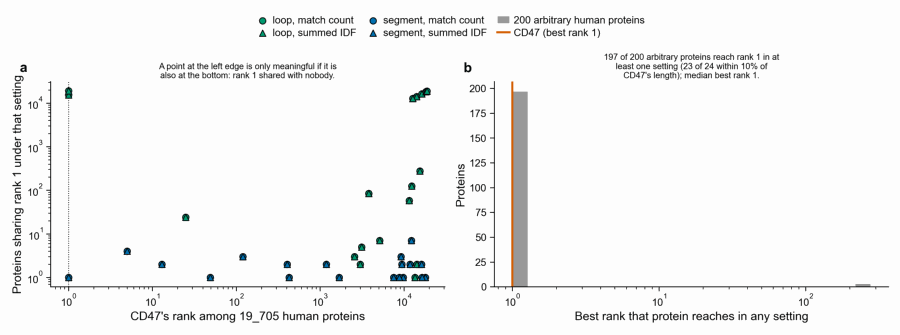

In [23]:
ranks = pl.read_csv(DATA / "34_cd47_rank_across_settings.csv")
control = pl.read_csv(DATA / "35_pretend_target_best_ranks.csv")
equiv = pl.read_csv(DATA / "36_metric_equivalence.csv")
print("Four metrics, one ranking:")
print(equiv)
print(f"\n{ranks.height} settings. CD47's rank, best first:")
print(
    ranks.sort("cd47_rank")
    .select(
        "alphabet",
        "n_classes",
        "query",
        "metric",
        "cd47_score",
        "best_score_in_proteome",
        "cd47_rank",
        "n_at_rank_1",
    )
    .head(12)
)
sole = ranks.filter((pl.col("cd47_rank") == 1) & (pl.col("n_at_rank_1") == 1))
print(f"\nSettings where CD47 is rank 1 and shares it with nobody: {sole.height}")
print(sole.select("alphabet", "query", "metric", "cd47_score", "n_at_rank_1"))
print(f"\nSettings where CD47 is rank 1 but the rank is shared:")
print(
    ranks.filter((pl.col("cd47_rank") == 1) & (pl.col("n_at_rank_1") > 1)).select(
        "alphabet", "query", "metric", "n_at_rank_1"
    )
)
nd = ranks.filter(pl.col("n_at_rank_1") <= 100)
print(
    f"\nCD47's best rank per query, over the {nd.height} settings that do not tie "
    f"more than 100 proteins at the top:"
)
print(
    nd.group_by("query")
    .agg(pl.col("cd47_rank").min().alias("best_rank"), pl.len().alias("n_settings"))
    .sort("query")
)
print(f"\nCONTROL, {control.height} arbitrary human proteins over the same settings:")
print(
    f"  reaching rank 1 somewhere: "
    f"{control.filter(pl.col('best_rank_over_all_settings') == 1).height}"
)
print(f"  median best rank: {control['best_rank_over_all_settings'].median()}")
matched = control.filter(pl.col("length_matched"))
print(
    f"  within 10% of CD47's length: "
    f"{matched.filter(pl.col('best_rank_over_all_settings') == 1).height} of "
    f"{matched.height} reach rank 1 somewhere"
)
show("276t_cd47_rank_across_settings", aspect=0.36)

**Figure 276t.** CD47's rank in every setting, and the control.
`figures/276t_cd47_rank_across_settings.png`. In panel **a** a point at the left edge only
means something if it is also at the bottom: rank 1 shared with nobody.

**Yes. Exactly one setting of the 76 makes CD47 the single best hit in the human proteome:**
`hsdm17`, the 36-residue segment, match count. CD47 scores 16 and **no other protein of the
19_705 reaches it**. That is the strongest statement anywhere in this notebook.

**It is also circular, and that is the end of it.** The segment P66 197-232 is not a stretch
of P66 chosen on its own merits. It is the window seed-and-extend produced *because* it
aligns to CD47, in section 6c, and section 6g showed it is one of only two places in P66
that reach this score against CD47. Section 6m runs the held-out test and settles it: with
CD47 held out, the data picks P66 159-194 instead, and CD47 ranks 4_696 of 19_705 for that
window. Asking whether CD47 tops a search for a query that was
carved out of its own best alignment is not a test of anything. The query already contains
the answer.

**The non-circular query is the loop, and CD47 never tops it.** P66 202-208 was chosen by
the paper without reference to CD47. Over the 18 loop settings that do not tie more than 100
proteins at the top, CD47's best rank is **25 of 19_705**, in `wass14`, where 897 proteins
share its score. The four loop settings that do put CD47 at rank 1 are `gbmr4` and
`hp_kyte_doolittle2`, which tie **15_409** and **19_028** proteins there: a 7-residue query
in a 2- or 4-class alphabet matches almost every protein in the proteome, so rank 1 is
meaningless.

**And "rank 1 in some setting" is worth nothing as a criterion.** Of 200 arbitrary human
proteins put through the identical sweep, **197 reach rank 1 in at least one of the 76
settings**, with a median best rank of 1. Restricted to the 24 that are within 10% of CD47's
length, 23 of 24 do. Sweeping settings will promote almost any protein to the top of
something, which is exactly why the earlier sections used a fixed setting and a matched
background instead of a sweep.

So the answer to the question has three parts, and only the second one is about biology.
There is one setting where CD47 is the unique best human match for a P66 query; that query
was defined by its match to CD47; and for the stretch the claim is actually about, the best loop rank is 25 of 19_705 (0.127%), shared with 897 proteins. This is
a high rank with many ties; it does not establish a unique match.

## 6m. The held-out test, and what CD47 actually has where the segment lands

Two things were left open. The held-out test, which is the only one that could
still rescue the rank-1 result. And what CD47's own annotation says about the stretch
the segment aligns to, which had been carried as residue numbers and never checked
against the entry.

**The held-out test.**

Hold CD47 out. Score every one of P66's 583 windows of 36 residues against the 437
matched human proteins that are not CD47, take the window that scores highest, and only
then ask where CD47 ranks for it. Alphabet `hsdm17`, window 36 and match count are fixed for this follow-up, after the earlier
CD47 comparison selected this setting, and the script asserts CD47 is absent from the discovery set before it runs.

In [24]:
heldout = pl.read_csv(DATA / "40_heldout_window_test.csv")
print(
    heldout.select(
        "window",
        "p66_span",
        "chosen_using_cd47",
        "held_out_score",
        "cd47_score",
        "best_score_in_proteome",
        "cd47_rank",
        "n_at_rank_1",
        "cd47_sole_first",
    )
)

shape: (2, 9)
┌─────────────────┬──────────┬───────────────────┬────────────────┬───┬────────────────────────┬───────────┬─────────────┬─────────────────┐
│ window          ┆ p66_span ┆ chosen_using_cd47 ┆ held_out_score ┆ … ┆ best_score_in_proteome ┆ cd47_rank ┆ n_at_rank_1 ┆ cd47_sole_first │
│ ---             ┆ ---      ┆ ---               ┆ ---            ┆   ┆ ---                    ┆ ---       ┆ ---         ┆ ---             │
│ str             ┆ str      ┆ bool              ┆ i64            ┆   ┆ i64                    ┆ i64       ┆ i64         ┆ bool            │
╞═════════════════╪══════════╪═══════════════════╪════════════════╪═══╪════════════════════════╪═══════════╪═════════════╪═════════════════╡
│ held-out choice ┆ 159-194  ┆ false             ┆ 15             ┆ … ┆ 15                     ┆ 4696      ┆ 8           ┆ false           │
│ circular window ┆ 197-232  ┆ true              ┆ 12             ┆ … ┆ 16                     ┆ 1         ┆ 1           ┆ true            │

**The window chosen without CD47 is P66 159-194.** It does not contain the loop and does
not overlap 197-232 at all. For that window CD47 ranks **4_696 of 19_705**, scoring 10
where the proteome's best is 15, tied with 6_641 other proteins.

**And P66 197-232 is an ordinary window against everything that is not CD47.** Its
held-out score is 12, which is the **median** over the 583 windows; 280 of them score
higher, and nine reach 15. Against CD47 it scores 16, which is the maximum any protein
reaches for it.

Both halves of that matter, and they point in opposite directions:

* **The original window was selected against CD47.** In this follow-up, with CD47 held out,
  the data picks a different part of the protein entirely, and CD47 is rank 4_696 for it.
  This particular window-selection procedure does not select it.
* **Given the window, the match is specific to CD47.** A window that is merely
  generically matchable would score well against the held-out set too. This one is median
  there and maximal on CD47, and section 6d already showed 0 of 437 matched proteins reach
  its score.

So this is a hypothesis-confirming result and not a hypothesis-generating one. If you
already suspect CD47, the segment is unusually good. This window-selection procedure did not select it.

**What CD47 has where the segment lands.**

CD47's SIRPalpha face is 21 residues in 11 runs, not 21 separate sites:
shape: (11, 4)
┌─────────┬────────────┬──────────┬──────────────────────────┐
│ span    ┆ n_residues ┆ sequence ┆ closest_contact_angstrom │
│ ---     ┆ ---        ┆ ---      ┆ ---                      │
│ str     ┆ i64        ┆ str      ┆ f64                      │
╞═════════╪════════════╪══════════╪══════════════════════════╡
│ 21      ┆ 1          ┆ L        ┆ 4.22                     │
│ 24      ┆ 1          ┆ K        ┆ 2.59                     │
│ 45      ┆ 1          ┆ N        ┆ 3.38                     │
│ 47-49   ┆ 3          ┆ EAQ      ┆ 3.38                     │
│ 52-53   ┆ 2          ┆ TE       ┆ 2.96                     │
│ 55      ┆ 1          ┆ Y        ┆ 3.38                     │
│ 57      ┆ 1          ┆ K        ┆ 2.82                     │
│ 64      ┆ 1          ┆ D        ┆ 2.59                     │
│ 67      ┆ 1          ┆ T        ┆ 3.85                     │
│ 115     ┆ 1          ┆ E     

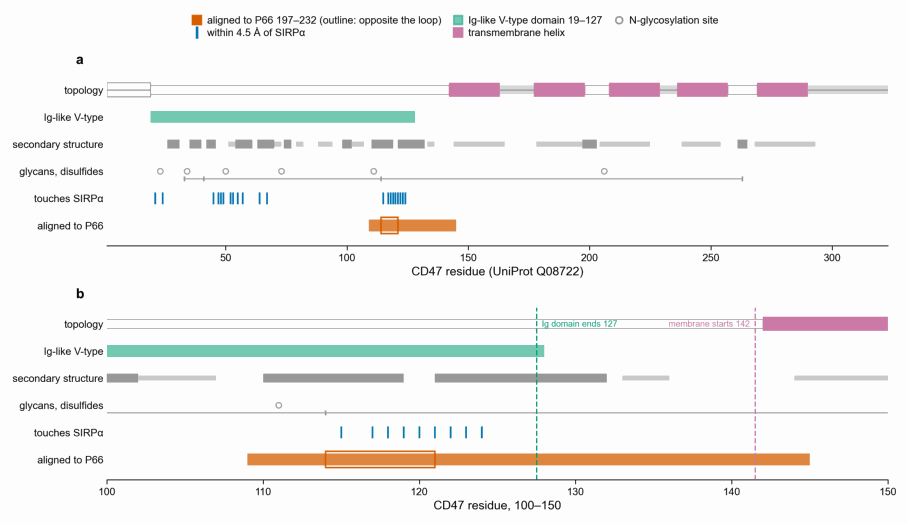

In [25]:
overlap = pl.read_csv(DATA / "41_cd47_feature_overlap.csv")
runs = pl.read_csv(DATA / "39_cd47_face_runs.csv")
print("CD47's SIRPalpha face is 21 residues in 11 runs, not 21 separate sites:")
print(runs)
print("\nUniProt features the aligned segment and the face overlap:")
print(overlap)
show("276u_cd47_feature_overlay", aspect=0.57)

**Figure 276u.** The face and the aligned segment drawn on CD47's own UniProt features.
`figures/276u_cd47_feature_overlay.png`.

**The face is one face, not 21 sites.** The 21 contact residues fall into **11 runs**, of
which 8 are single residues. The longest is **117-124**, `TELTREGE`, 8 residues. They span
21 to 124, so 104 residues of chain hold the 21 that touch, and all 21 are inside the
immunoglobulin domain. That is the N-terminal end plus loops at one end of the domain,
which is the convoluted interface the Hatherley paper describes rather than a flat patch.

**A number in section 6c was loose and is corrected here.** The segment was described as
"92% inside CD47's ectodomain". That is right for the extracellular topological domain,
19-141, but the **immunoglobulin domain itself ends at 127**. Of the segment's 36 CD47
columns: **19 are in the Ig-like V-type domain (53%)**, 33 are extracellular, and **3 are
inside the first transmembrane helix**, which starts at 142. The segment runs off the end
of the domain and into the membrane.

Two more things sit in it that a mimicry account would have to deal with:

* **An N-linked glycosylation site at CD47 111**, two residues inside the segment. A real
  glycan there is far larger than a side chain.
* **The cysteine at CD47 114 is locked in a disulfide to residue 41** — and 114 is the
  first residue of `CEVTELT`, the stretch sitting opposite the P66 loop. That cysteine is
  not available to do anything else.

So the part of CD47 opposite the claimed loop is a disulfide-pinned cysteine followed by
six residues at the far end of the domain, five of which do touch SIRPalpha, immediately
downstream of a glycosylation site, in a segment that runs out of the domain and into the
membrane three columns later.

## 7. Citations

Every paper here was looked up with the PubMed tool in this session and the metadata it
returned is pasted below; no DOI, PMID or URL is written from memory. According to PubMed:

| what it is cited for | paper | PMID | DOI |
|---|---|---|---|
| the mimicry claim under test | Tal MC, Hansen PS, Ogasawara HA, *et al.* "P66 is a bacterial mimic of CD47 that binds the anti-phagocytic receptor SIRPα and facilitates macrophage evasion by." *bioRxiv*, 30 April 2024 | 38746193 | [10.1101/2024.04.29.591704](https://doi.org/10.1101/2024.04.29.591704) |
| PDB 2JJS, the CD47 / SIRPα complex the face is measured from | Hatherley D, Graham SC, Turner J, Harlos K, Stuart DI, Barclay AN. "Paired receptor specificity explained by structures of signal regulatory proteins alone and complexed with CD47." *Mol Cell* 31(2):266-77, 25 July 2008 | 18657508 | [10.1016/j.molcel.2008.05.026](https://doi.org/10.1016/j.molcel.2008.05.026) |
| P66 as an integrin ligand, the measured part of the loop's function | Coburn J, Cugini C. "Targeted mutation of the outer membrane protein P66 disrupts attachment of the Lyme disease agent, *Borrelia burgdorferi*, to integrin alphavbeta3." *Proc Natl Acad Sci USA* 100(12):7301-6, 14 May 2003 | 12748384 | [10.1073/pnas.1131117100](https://doi.org/10.1073/pnas.1131117100) |
| US-align, comparisons 1 and the superposition | Zhang C, Shine M, Pyle AM, Zhang Y. "US-align: universal structure alignments of proteins, nucleic acids, and macromolecular complexes." *Nat Methods* 19(9):1109-1115, 29 August 2022 | 36038728 | [10.1038/s41592-022-01585-1](https://doi.org/10.1038/s41592-022-01585-1) |
| Foldseek, comparison 2 | van Kempen M, Kim SS, Tumescheit C, Mirdita M, Lee J, Gilchrist CLM, Söding J, Steinegger M. "Fast and accurate protein structure search with Foldseek." *Nat Biotechnol* 42(2):243-246, 8 May 2023 | 37156916 | [10.1038/s41587-023-01773-0](https://doi.org/10.1038/s41587-023-01773-0) |
| the AlphaFold models and what pLDDT means | Varadi M, Anyango S, Deshpande M, *et al.* "AlphaFold Protein Structure Database: massively expanding the structural coverage of protein-sequence space with high-accuracy models." *Nucleic Acids Res* 50(D1):D439-D444, 7 January 2022 | 34791371 | [10.1093/nar/gkab1061](https://doi.org/10.1093/nar/gkab1061) |

Two things in this notebook have no citation that could be fetched:

* **The P-SEA CA-geometry criteria used to call coil in section 5.** I cannot verify a
  citation for this claim: PubMed returned nothing for the P-SEA paper under several
  queries. The criteria are stated in the code so a reader can check them directly, and
  they affect only which 10 background loops were drawn, not any measurement.
* **The claim that the loop is "a predicted extracellular loop".** The quoted preprint
  asserts it; no separate citation was fetched for the topology prediction itself.

## 8. Summary and conclusions

**Does the structure support mimicry? No, on all three comparisons, and the claimed pair
loses to both backgrounds.**

| comparison | the claimed pair | the background | beats it? |
|---|---|---|---|
| whole fold, TM-score against CD47's IgV domain | 0.342, 68 residues aligned, 4.34 Å RMSD | 20 immunoglobulin domains, 0.507 to 0.704, median 0.614 | no, below all 20 |
| Foldseek against the PDB | best E = 0.128, no CD47 entry in 176 hits, although 2JJS is in the database | nothing below E = 0.001 at all; top hits are bacterial outer-membrane β-barrels | no hit to beat |
| the loop on the binding face, backbone RMSD | 1.91 Å, best window CD47 29-35 | 10 other P66 loops, 0.94 to 1.82 Å, median 1.07 Å | no, worst of 11 |

Claim sentences:

* **P66's AlphaFold model does not share CD47's immunoglobulin fold**: TM-score 0.342
  normalised by CD47, below the 0.5 same-fold line and below all 20 unrelated
  immunoglobulin domains, whose lowest score is 0.507.
* **Foldseek finds P66 to be a bacterial outer-membrane β-barrel and finds no CD47**: the
  176 PDB hits are led by FapF and PagP at E = 0.128, no hit reaches E = 0.001, and no CD47
  or SIRPα entry appears even though 2JJS is in the searched database.
* **The loop in the claim fits CD47's SIRPα-binding face worse than ordinary P66 loops
  do**: 1.91 Å backbone RMSD against a median of 1.07 Å for 10 other 7-residue P66 loops,
  and in the whole-fold superposition its centre lands 55 Å from the centre of the face,
  off a domain only 45 Å across at its widest.
* **No tested setting makes CD47 the unique top hit for the loop.**
  Over 76 settings, CD47's best rank for a P66 202-208 query is 25 of 19_705 once settings
  that tie more than 100 proteins at the top are excluded, and the settings that do rank it
  first tie 15_409 or 19_028 proteins there. One setting makes CD47 the unique best hit for
  the 36-residue segment, `hsdm17` with a match count, but that query was carved out of its
  own alignment to CD47. The control settles the method: 197 of 200 arbitrary human proteins
  also reach rank 1 in at least one of the 76 settings.
* **kmerseek's silence on exact k-mers is forced, and carries no weight either way**: none
  of the 326 shared k-mers touches the loop across the 16 alphabets and 27 settings PR 96
  searched, and at every one of those settings no k-mer covering the loop occurs in CD47 at
  all. 8 of 19 alphabets write the loop's seven polar residues as one repeated class; in the
  other 11 the string varies but its k-mers are almost all absent from CD47 anyway (3
  k-mers in total, all at k = 5). The zero says where the sweep looked, not whether the
  mimicry is real.
* **Seed-and-extend finds one real sequence similarity, and it is not the loop.** `hsdm17`
  and `sdm12` both find a 36-residue ungapped segment, P66 197-232 against CD47
  109-144, 53% inside the immunoglobulin domain and 92% extracellular, covering 9 of the
  21 SIRPalpha-face residues.
  The two are not independent of each other: section 6j shows they accept the same four
  non-identical residue pairs and the segment's signal over chance is carried by one of
  them, `K` against `E`. It
  passes a prespecified test: 0 of 437 human proteins matched to CD47 on length and acidic
  fraction reach its score (observed background fraction 0/437, not a bound p < 0.002). But splitting the same background by column, CD47
  scores 5.0 on the 29 flanking columns where no matched protein reaches it, and 1.0 on the
  loop's 7 columns where **all 12 matched proteins that reach the loop beat it**, median
  3.5. CD47 is the best of 438 on the part of the segment the claim is not about and the
  worst of 13 on the part it is. A convergent functional mimic should be strongest where
  the function is, so this counts mildly against the loop rather than for it.

### The strongest argument against this result

**The P66 model is too poor to settle anything, and that cuts against the negative as hard
as it cuts against the claim.** Mean pLDDT 29.0, with 99.8% of residues below AlphaFold's
"very low" line of 50, and no experimental structure to fall back on. TM-score, Foldseek's
3Di alphabet and a backbone RMSD all read the coordinates as if they meant something, and
here they may not. A TM-score of 0.342 against CD47 is what a wrong model would give as
readily as what a genuinely different fold would give.

Three things limit how far that objection goes, and none of them removes it:

1. Foldseek still recovers the right biology from the same model: its best hits are
   outer-membrane β-barrels, which is what P66 is known to be. A model carrying no usable
   signal would not do that.
2. Comparison 3 is internally fair. The claimed loop and the 10 background loops come from
   the same bad model, so whatever the model gets wrong, it gets wrong for all of them.
3. The paper's own figure cites an AlphaFold2 model of P66 for the same loop. If the model
   is too poor to test the claim, it is also too poor to have supported it.

The sequence side adds one thing the structure cannot: the P66 197-232 similarity to CD47
109-144 is real, specific against a matched background (0 of 437 matched human proteins and
0 of 239 immunoglobulin domains reach it), one of two such regions in P66, corroborated
by 7 of 19 alphabets and by none with fewer than 7 classes, though not by 7 independent
routes, and strongest 5 to
24 residues away from the loop. Whatever it is, it is not the claim, and it would be worth a look on its own
terms.

The way to settle this is a better structure, not a better analysis: an experimental P66
structure, or a model built with a deeper alignment than the AlphaFold database entry
carries, and then a direct test of P66 against SIRPα rather than against CD47. The
mimicry claim's own measured evidence is binding and genetics, which this notebook does not
touch and does not contradict. What it does say is that nothing in the shape of the only
public P66 structure supports mimicry, and that the shortest stretch of it the claim rests
on fits CD47's binding face worse than the protein's other loops do.